<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/15_Smart_Grid_Power_System_Attacks/QUPID_SmartGridAnomaly_Ngo2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QUPID, a partitioned quantum neural network for smart-grid anomaly detection: Ngo et al. (2026) step by step

This notebook re-implements, runs and checks the method of

> Hoang M. Ngo, Tre' R. Jeter, Jung Taek Seo and My T. Thai, "QUPID: A Partitioned Quantum Neural Network for Anomaly
> Detection in Smart Grid", arXiv:2601.11500 [cs.LG], January 2026. https://arxiv.org/abs/2601.11500

The paper publishes no code. Everything below is written from the paper's text, with the software stack it names:
PennyLane for the quantum circuits, scikit-learn for the scaler, the split and the metrics, and a neural-network
framework (PyTorch here) for the classical dense layers and the gradient-based training.

**What the notebook does.**
1. Downloads the public Mississippi State University / Oak Ridge National Laboratory *power system attack* data
   (15 sampled files, 37 event scenarios each; the paper's "ICS dataset", S1 to S15) and groups the 37 events into six classes.
2. Rebuilds the paper's pre-processing (drop the constant log columns, MinMax scaling fitted on the training split, 70 : 30 split).
3. Turns each of the four phasor measurement units (PMUs) into one **partition**: 13 complex phasors (magnitude times
   `exp(j * angle)`) plus a few real values are amplitude-encoded into a **5-qubit** circuit, so that the whole model
   uses 4 x 5 = 20 qubits. Each circuit has 3 layers of `RY`/`RZ` rotations with a circular `CNOT` ring and returns one
   Pauli-Z expectation per qubit; the four result vectors are concatenated and sent through two dense layers and a softmax.
4. Trains QUPID (Adam, learning rate 0.01, batch size 128, up to 200 epochs as in the paper) and compares it with
   an MLP, a random forest, an RBF SVM and a hybrid quantum-classical DNN (the paper's "HQ-DNN")
   trained on exactly the same scaled inputs.
5. Re-draws the paper's Table I (seven metrics per scenario) and the robustness study of its Figure 3: FGSM and PGD attacks
   against QUPID, against **R-QUPID** (QUPID with classical Gaussian input noise and a depolarizing channel) and against
   an MLP with Gaussian input noise.
6. Prints the paper's numbers next to ours with a verdict per claim, followed by a critical reading and exercises.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs
a pinned PennyLane (and `py7zr` for the 7z data archive); if Colab asks to restart the session, restart and run all
again. No GPU and no quantum-cloud account are needed; `FAST_MODE = True` (default) is the ten-minute class demo.

**Runtime.** With `FAST_MODE = True` (scenarios S1-S3, 20 epochs, short robustness study) the notebook took about 4 minutes on the validation machine, a shared laptop CPU with one torch thread; expect 5-10 minutes on a Colab CPU. With `FAST_MODE = False` (all 15 scenarios, the paper's 200 epochs for QUPID, three extra seeds, the full robustness grid) it took about one hour there; expect one to two hours on Colab. The committed notebook contains the outputs of the full run (the last line printed in Section 8 states its runtime).

**What you get at the end.** Accuracy, weighted precision / recall / F1, one-vs-rest ROC-AUC, MCC and G-mean for five models on
each scenario, confusion matrices, training curves, the adversarial-robustness curves, and a paper-versus-notebook table.

## The paper in one page

**Problem.** A transmission grid (two generators, four breakers BR1-BR4, four protective relays / intelligent electronic
devices R1-R4, two lines L1 and L2, four PMUs) is simulated in a hardware-in-the-loop testbed. At each time stamp the
operator must decide which of several situations is happening: normal operation, a natural event (short-circuit fault or line
maintenance) or a cyber attack (remote tripping command injection, relay setting change, data injection). Deciding wrongly
either blacks out a line (a missed attack) or raises false alarms.

**Decision.** A 6-class label per sample. The dataset has 37 event scenarios (42 "classes" in the paper's wording) that the
authors "subcategorized into 6 classes, labeled 0-5"; the paper does not say which events go into which class (see the
choices table below).

**Method (Section IV, Figure 1).**
- The grid state is `x = [x(1), ..., x(n)]`, one block per PMU. A PMU reports voltage and current magnitudes and angles for the
  three phases and for the positive / negative / zero sequence components, i.e. 12 **complex phasors** `V e^{j alpha}` and `I e^{j beta}` (Section IV.A).
- The `n` PMUs are grouped into `K` partitions of neighbouring PMUs; each partition feeds one small parameterised quantum circuit
  (PQC) `C(k)` on `q = log2(t * m)` qubits, so the model needs `O(K log2(t m))` qubits instead of one circuit for all inputs.
- Experiments (Section V): **four 5-qubit circuits (20 qubits in total)**, each encoding "up to 32 complex-valued inputs" by
  **amplitude embedding**; the ansatz has **3 alternating layers of single-qubit `RY`/`RZ` rotations and a circular `CNOT` ring**.
- Each circuit returns a latent vector `h(k)` of Pauli-Z expectation values; `h = [h(1), ..., h(K)]` goes through two dense layers
  with ReLU activations, then a softmax. Cross-entropy loss, **Adam, learning rate 1e-2, batch size 128, 200 epochs**.
- **R-QUPID** (Section IV.C) adds a classical Gaussian mechanism `A` on the input (sigma = sqrt(2 ln(1.25/delta)) * Delta * L / epsilon)
  and a depolarizing channel `E_p(rho) = (1-p) rho + p I/d` after the ansatz; Lemma 4 and Theorem 1 state that the combination is
  `(epsilon, (1-p) sqrt(1-phi) delta)`-differentially private and certifiably robust when `E[y_c] > e^(2 K epsilon) max E[y_i] + ...`.

**Data (Section V).** Morris' "Industrial control system (ICS) cyber attack datasets" (ORNL / MSU power system attack data):
15 scenarios S1-S15, 128 features per sample (4 PMUs x 29 measurements + 12 log columns), 8 zero-variance log columns removed, input
IDs removed, "119 total features". `MinMaxScaler`, **70 / 30 split**.

**Baselines.** MLP (scikit-learn defaults), InceptionNet, MTL-LSTM, HQ-DNN (two dense layers, then a `RY`/`CNOT` variational circuit),
FTTransformer, each "with the hyperparameters of their papers".

**Claims to check.**
- Table I (six models x 15 scenarios x 7 metrics: accuracy, precision, recall, F1, ROC-AUC, MCC, G-mean). QUPID's mean accuracy over S1-S15 is 0.920
  (MLP 0.821, InceptionNet 0.786, MTL-LSTM 0.861, HQ-DNN 0.796, FTTransformer 0.916). "QUPID outperforms every baseline across all
  metrics for the majority of scenarios (at least 8 of 15)", dominates S1, S3, S11, S12, and has the highest recall and F1 in 10 of 15 scenarios.
- Inference time below 0.1 s per instance for all models.
- Figure 3 (robustness): FGSM and PGD with attack bounds 0.05 and 0.1. R-QUPID reaches about 81 % and 70 % under FGSM (baselines about 10 and 5 points lower)
  and about 79 % and 70 % under PGD (baselines about 8 and 3 points lower), for classical noise levels sigma^2 between 0.05 and 0.9 on the baselines.
- Theory (Lemmas 1-5, Theorem 1): privacy amplification and certified robustness (not an experiment; only a numerical sanity check of Lemma 3 is possible).

## What follows the paper and what had to be chosen

The paper is a short conference-style text. It is silent on several things that change the numbers, so each gap is filled with
a visible `# CHOICE:` in the code. The table lists them in the order they appear.

| Item | Paper | This notebook |
|---|---|---|
| Data source | UAH page of T. Morris (ORNL / MSU data) | That page's links (`www.ece.uah.edu/~thm0009/icsdatasets/multiclass.7z`) now return HTTP 404. The notebook downloads the **same file from the Internet Archive** (capture of 2024-04-29) and checks its SHA-256 against the value recorded by an independent benchmark that downloaded it from UAH in 2026 (`ba27c1fa...`). |
| 6 classes | "subcategorized into 6 classes, labeled 0-5" (grouping not given) | 0 normal operation (scenario 41), 1 short-circuit faults (1-6), 2 line maintenance (13, 14), 3 data injection (7-12), 4 remote tripping command injection (15-20), 5 relay setting change (21-30, 35-40). Follows the taxonomy of the paper's Section III.A and the dataset README. |
| Features | 128 columns, "119 total features" after removing 8 zero-variance columns and the input IDs | The 8 columns the paper names (4 `control_panel_log`, 4 `snort_log`) are removed: **120 features**. We cannot tell which further column the paper dropped. |
| Missing values | not mentioned | Infinite impedances (`R#-PA:Z`) become NaN and are replaced by the **training-split median**. |
| Partition | K = 4 groups of neighbouring PMUs, 5 qubits each | One PMU per partition (PMU k together with the log column of its relay `relayk_log`), which is the natural reading of "four 5-qubit circuits". |
| Complex encoding | `V e^{j alpha}` phasors, amplitude embedding of "up to 32 complex values" | Per partition 13 complex phasors (12 V / I phasors + the apparent impedance `Z e^{j ZH}`) built from the **MinMax-scaled magnitude** and the **physical angle**, plus 4 real values (frequency, frequency change, status flag, relay log), zero-padded to 32 amplitudes, then normalised (amplitude embedding). |
| Read-out | Pauli-Z expectation, "latent vector in R^(log2 q)" (inconsistent) | One `<Z>` per qubit: 5 values per circuit, 20 in total. |
| Dense layers | two layers with ReLU, `softmax(ReLU(...))` | `BatchNorm -> Linear(20, 128) -> ReLU -> Linear(128, 6)` and a softmax. The last ReLU of the paper's formula is left out: it zeroes logits and stalls training (checked while building this notebook). The BatchNorm and the width 128 are our additions. |
| Simulator | PennyLane, 20 qubits | PennyLane circuits for the definition and for a numerical equivalence check; **training uses an exactly equivalent tensor implementation** of the same 5-qubit circuit (the ansatz unitary is built from the same gates and applied to the whole batch), because PennyLane's gate-by-gate backpropagation was about 15 times slower on this CPU. The four 5-qubit circuits act on separate registers, so four simulations equal the 20-qubit one. |
| Training | Adam, 1e-2, batch 128, 200 epochs | Same. Initial rotation angles uniform in [0, 2 pi) (not given). |
| Baselines | MLP, InceptionNet, MTL-LSTM, HQ-DNN, FTTransformer with their papers' hyperparameters | MLP (scikit-learn defaults, as in the paper) and a compact HQ-DNN (widths not given), plus a random forest and an RBF SVM. **InceptionNet, MTL-LSTM and FTTransformer are not re-run** (a compact FT-Transformer written for this notebook cost 5-20 s per epoch on a CPU and did not leave the majority-class solution in the epochs we could afford, so it would only mislead); their paper numbers are quoted in Section 8. |
| Metrics | accuracy, precision, recall, F1, ROC-AUC, MCC, G-mean (averaging not stated) | Weighted-average precision / recall / F1 (the paper's MLP recall equals its accuracy, which is what weighting gives), one-vs-rest weighted ROC-AUC, multi-class MCC, G-mean = class-frequency-weighted mean of `sqrt(TPR * TNR)`. |
| Robustness | FGSM / PGD with bounds 0.05 and 0.1; scenario, step counts, noise scale not given; baselines with classical noise sigma^2 in [0.05, 0.9] | Scenario S1, L-infinity bounds 0.05 and 0.1 on the MinMax-scaled inputs, PGD with 10 steps of size eps / 4 and a random start, white-box gradients through the deployed (noisy) model. Gaussian noise **standard deviations** 0, 0.02, 0.05 (a variance of 0.05 would mean sigma = 0.22 on inputs that live in [0, 1]), depolarizing p, and finite-shot sampling noise are our grid. |
| Seeds | not stated | `SEED = 42` everywhere. |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and PyTorch.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" py7zr
    print("PennyLane installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install (py7zr is installed on demand when the 7z archive is unpacked).")
if importlib.util.find_spec("torch") is None:
    %pip install -q torch --index-url https://download.pytorch.org/whl/cpu

pennylane already present; skipping pip install (py7zr is installed on demand when the 7z archive is unpacked).


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False            # True: 3 scenarios, short training, a few minutes. False: all 15 scenarios, 200 epochs (the paper's budget).
SEED      = 42              # CHOICE: the paper gives no seed

SCENARIOS = [1, 2, 3] if FAST_MODE else list(range(1, 16))   # paper: S1-S15 (the 15 files data1 ... data15)
TEST_SIZE = 0.30            # paper: 70 / 30 split (stratified here)
N_QUBITS  = 5               # paper: four 5-qubit circuits, 32 amplitudes each
N_PARTS   = 4               # paper: K = 4 partitions (one per PMU here)
N_LAYERS  = 3               # paper: 3 alternating layers of RY/RZ rotations and a circular CNOT ring
EPOCHS    = 20 if FAST_MODE else 200      # paper: 200 epochs
BATCH     = 128             # paper: batch size 128
LR        = 1e-2            # paper: Adam, learning rate 1e-2
HIDDEN    = 128             # CHOICE: width of the first dense layer (not given)
BASE_EPOCHS = 15 if FAST_MODE else 60     # CHOICE: epochs for the neural baseline HQ-DNN (not given)
SEED_REPEATS = 1 if FAST_MODE else 3      # extra seeds of QUPID on the first scenario (mean +- std)

# robustness study (paper Figure 3)
ROBUST_SCENARIO = 1
ROBUST_EPOCHS   = 15 if FAST_MODE else 100   # CHOICE: epochs for the noisy models of the robustness study
ROBUST_TEST_N   = 400 if FAST_MODE else 1000 # CHOICE: test samples attacked
ATTACK_EPS      = [0.05, 0.10]               # paper: attack bounds 0.05 and 0.1
PGD_STEPS       = 5 if FAST_MODE else 10     # CHOICE: PGD iterations (step size eps / 4)
NOISE_SIGMAS    = [0.0, 0.02] if FAST_MODE else [0.0, 0.02, 0.05]   # CHOICE: Gaussian input-noise standard deviations
DEPOL_P         = [0.0, 0.2]                 # CHOICE: depolarizing strengths for R-QUPID
SHOTS           = 1000                       # CHOICE: shots per expectation value in the noisy (R-QUPID) circuits

DATA_DIR = "ics_power_data"
DATA_URLS = [   # primary (dead since 2025/26) and archived copies of the same file
    "http://www.ece.uah.edu/~thm0009/icsdatasets/multiclass.7z",
    "https://web.archive.org/web/20240429204938id_/http://www.ece.uah.edu/~thm0009/icsdatasets/multiclass.7z",
    "https://web.archive.org/web/2id_/http://www.ece.uah.edu/~thm0009/icsdatasets/multiclass.7z",
]
DATA_SHA256 = "ba27c1fa81c53fe2718734b9c6311a41b93cd73c86de0f86e59566a6d70e8555"   # recorded by an independent benchmark (QuantumGridBench)
LOCAL_ARCHIVE = ""          # optional: path of a multiclass.7z (or of a folder with the 15 ARFF files) that you uploaded yourself
IBM_TOKEN = ""              # unused here: every circuit runs on a simulator (kept for convention)

In [3]:
import os, time, json, subprocess, shutil, hashlib, warnings, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import torch, torch.nn as nn
import pennylane as qml
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, roc_auc_score,
                             matthews_corrcoef, confusion_matrix, ConfusionMatrixDisplay)

torch.manual_seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(1)      # the matrices here are tiny: one thread is faster than several
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
T_NOTEBOOK_START = time.time()
print("pennylane", qml.__version__, "| torch", torch.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| scenarios:", SCENARIOS, "| epochs:", EPOCHS)

pennylane 0.45.1 | torch 2.14.1+cpu | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = False | scenarios: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15] | epochs: 200


## 1. The power-system attack data

The data were produced by Mississippi State University and Oak Ridge National Laboratory (Pan, Morris, Adhikari; Beaver,
Borges et al.) on the grid of Figure 2 of the paper. A simulation runs one of 37 event scenarios (numbered 1 to 41 with gaps)
and the PMUs, the relays, a control panel and the intrusion detector Snort are logged; each of the 15 released files is a random
1 % sample of the whole simulation, with 128 numeric columns and the scenario number as the label (`marker`). These 15 files are the paper's S1 to S15.

The next cell downloads the multi-class archive (20 MB), checks its checksum, unpacks the 15 ARFF files and reads them. ARFF is
a plain-text format of the Weka tool: `@attribute` lines name the columns, the lines after `@data` are comma-separated rows.

In [4]:
def download_archive():
    path = os.path.join(DATA_DIR, "multiclass.7z")
    if os.path.exists(path) and hashlib.sha256(open(path, "rb").read()).hexdigest() == DATA_SHA256:
        return path
    import requests
    for url in DATA_URLS:
        try:
            r = requests.get(url, timeout=120, headers={"User-Agent": "Mozilla/5.0"})
            if r.status_code == 200 and hashlib.sha256(r.content).hexdigest() == DATA_SHA256:
                open(path, "wb").write(r.content); print("downloaded", url, f"({len(r.content)/1e6:.1f} MB), checksum OK"); return path
            print("skipped", url, "-> HTTP", r.status_code, "or checksum mismatch")
        except Exception as e:
            print("skipped", url, "->", type(e).__name__)
    raise RuntimeError("could not download multiclass.7z; set LOCAL_ARCHIVE to a copy you downloaded yourself")

def unpack_archive(path, out_dir):
    os.makedirs(out_dir, exist_ok=True)
    try:
        import py7zr
        with py7zr.SevenZipFile(path) as z: z.extractall(out_dir)
        return
    except ImportError:
        pass
    for cmd in (["tar", "-xf", path, "-C", out_dir], ["7z", "x", "-y", "-o" + out_dir, path]):   # bsdtar (Windows / macOS) or 7-Zip
        try:
            if subprocess.run(cmd, capture_output=True).returncode == 0 and any(f.endswith(".arff") for _, _, fs in os.walk(out_dir) for f in fs):
                return
        except FileNotFoundError:
            pass
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "py7zr"], check=True)
    import py7zr
    with py7zr.SevenZipFile(path) as z: z.extractall(out_dir)

def find_arff_dir():
    if LOCAL_ARCHIVE and os.path.isdir(LOCAL_ARCHIVE): return LOCAL_ARCHIVE
    out_dir = os.path.join(DATA_DIR, "multiclass")
    if not any(f.endswith(".arff") for _, _, fs in os.walk(out_dir) for f in fs):
        unpack_archive(LOCAL_ARCHIVE if LOCAL_ARCHIVE else download_archive(), out_dir)
    for root, _, files in os.walk(out_dir):
        if any(f.endswith(".arff") for f in files): return root
    raise RuntimeError("no ARFF files found")

def read_arff(path):
    names, skip = [], 0
    with open(path, "r", errors="ignore") as f:
        for i, line in enumerate(f):
            low = line.lower()
            if low.startswith("@attribute"): names.append(line.split()[1])
            elif low.startswith("@data"): skip = i + 1; break
    return pd.read_csv(path, skiprows=skip, header=None, names=names)

ARFF_DIR = find_arff_dir()
RAW = {}
for k in range(1, 16):
    fn = [f for f in os.listdir(ARFF_DIR) if f.startswith(f"data{k} ") and f.endswith(".arff")][0]
    RAW[k] = read_arff(os.path.join(ARFF_DIR, fn))
print("ARFF folder:", ARFF_DIR)
print("scenario files read:", len(RAW), "| total rows:", sum(len(d) for d in RAW.values()), "| columns per file:", RAW[1].shape[1], "(128 features + marker)")

ARFF folder: ics_power_data\multiclass
scenario files read: 15 | total rows: 78377 | columns per file: 129 (128 features + marker)


### 1.1 From 37 events to 6 classes

The README of the data set groups the 37 scenarios into natural events (short-circuit faults 1-6, line maintenance 13-14),
the normal operation 41, and attacks: data injection (7-12), remote tripping command injection (15-20) and relay setting change (21-30, 35-40).
The paper's Section III.A names exactly these families, so the 6 classes below are normal operation, short-circuit fault, line
maintenance and the three attack families. **CHOICE:** the paper does not list the grouping; other groupings give different numbers.

,S1,S2,S3,S4,S5,S6,S7,S8,S9,S10,S11,S12,S13,S14,S15
normal operation,173,322,354,403,270,190,208,356,478,326,145,384,203,79,514
short-circuit fault,663,881,1014,1204,1035,1054,925,1039,1133,977,843,1264,844,923,1201
line maintenance,264,341,236,193,176,233,193,149,159,345,294,123,106,351,146
data injection,569,581,573,619,773,533,675,738,660,730,816,704,581,595,435
remote tripping,452,583,345,557,609,524,705,738,568,518,552,639,622,586,739
relay setting change,2845,2361,2893,2226,2298,2433,2530,2295,2342,2673,2601,2110,2915,2581,2241


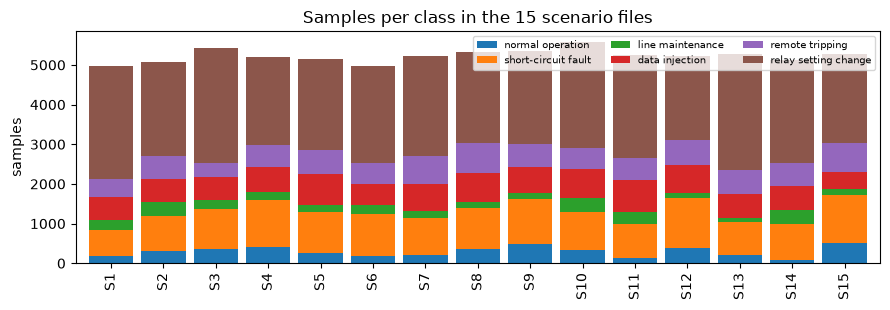

In [5]:
CLASS_NAMES = ["normal operation", "short-circuit fault", "line maintenance", "data injection", "remote tripping", "relay setting change"]
def to_class(m):
    if m == 41: return 0                       # CHOICE: grouping of the 37 scenarios into 6 classes
    if 1 <= m <= 6: return 1
    if m in (13, 14): return 2
    if 7 <= m <= 12: return 3
    if 15 <= m <= 20: return 4
    return 5                                   # 21-30, 35-40: relay setting change (single / double relay disabled, with a fault or maintenance)
ATTACK_CLASSES = (3, 4, 5)

counts = pd.DataFrame({f"S{k}": np.bincount(RAW[k]["marker"].astype(int).map(to_class), minlength=6) for k in RAW}, index=CLASS_NAMES)
display(counts)
fig, ax = plt.subplots(figsize=(9, 3.2))
counts.T.plot(kind="bar", stacked=True, ax=ax, width=0.85)
ax.set_ylabel("samples"); ax.set_title("Samples per class in the 15 scenario files"); ax.legend(fontsize=7, ncol=3)
plt.tight_layout(); plt.show()

## 2. Cleaning and pre-processing (paper, Section V "Dataset")

The paper removes eight columns that have zero variance (4 control-panel logs and 4 Snort logs) and the identifier, scales with
`MinMaxScaler` and splits 70 / 30. As everywhere in this repository, **every transform is fitted on the training split only**:
the median used to replace the infinite impedances (`R#-PA:Z` is infinite when the current is zero) and the minimum / maximum of the scaler.
The test split is clipped to [0, 1] after scaling. The stratified split keeps the class mix of the scenario in both halves.

The function below also records the training minimum and maximum of every column. They are needed in Section 3 to turn the scaled
angles back into physical angles and by the adversarial attacks of Section 8, which perturb the *scaled* inputs.

In [6]:
LOG_DROP_PREFIX = ("control_panel_log", "snort_log")       # the 8 columns the paper removes (zero variance in its data)

def prepare(k, seed=SEED):
    df = RAW[k].copy()
    y = df.pop("marker").astype(int).map(to_class).values
    df = df.drop(columns=[c for c in df.columns if c.startswith(LOG_DROP_PREFIX)]).replace([np.inf, -np.inf], np.nan)
    cols = list(df.columns)
    Xtr, Xte, ytr, yte = train_test_split(df.values.astype(float), y, test_size=TEST_SIZE, stratify=y, random_state=seed)
    imp = SimpleImputer(strategy="median").fit(Xtr)                       # fitted on the training split only
    Xtr, Xte = imp.transform(Xtr), imp.transform(Xte)
    mm = MinMaxScaler().fit(Xtr)
    return dict(k=k, cols=cols, Xtr=mm.transform(Xtr), Xte=np.clip(mm.transform(Xte), 0.0, 1.0), ytr=ytr, yte=yte,
                dmin=mm.data_min_, dmax=mm.data_max_, nan_frac=float(df.isna().mean().mean()),
                n_const=int((mm.data_max_ == mm.data_min_).sum()))

D1 = prepare(SCENARIOS[0])
COLS = D1["cols"]
print(f"scenario S{D1['k']}: {len(COLS)} features | train {D1['Xtr'].shape} test {D1['Xte'].shape} | NaN share (infinite impedance) {D1['nan_frac']:.3%} | constant columns {D1['n_const']}")
print("class mix train:", np.bincount(D1["ytr"], minlength=6).tolist(), "test:", np.bincount(D1["yte"], minlength=6).tolist())

scenario S1: 120 features | train (3476, 120) test (1490, 120) | NaN share (infinite impedance) 0.112% | constant columns 1
class mix train: [121, 464, 185, 398, 316, 1992] test: [52, 199, 79, 171, 136, 853]


## 3. Partitions and complex phasor encoding (paper, Section IV.A-B)

Each of the four PMUs measures 29 quantities: voltage and current **magnitude and angle** for the three phases (A, B, C) and for the
positive, negative and zero sequence components (24 numbers), plus the frequency, the frequency change, the apparent impedance
(magnitude and angle) and a status flag of the relay. The relay logs (`relay1_log` to `relay4_log`) belong to the same four devices.

The paper writes the 12 voltage and current measurements of a PMU as complex phasors, `V e^(j alpha)` and `I e^(j beta)`.
In this notebook:

- the **magnitude** is the MinMax-scaled column (in [0, 1]), the **angle** is the physical angle recovered from the scaled column with the
  training minimum / maximum (degrees for the 12 V / I angles, radians for the impedance angle `ZH`);
- the 12 V / I phasors and the apparent impedance `Z e^(j ZH)` give **13 complex numbers**; frequency, frequency change, status flag and
  relay log are added as 4 real numbers, so each partition has 17 complex amplitudes; **CHOICE:** the remaining 15 of the 32 amplitudes are zero;
- the 32-vector is normalised to unit length, which is what *amplitude embedding* does, and loaded into **5 qubits** (`2^5 = 32`).

One partition per PMU gives `K = 4` circuits and 20 qubits in total. Because the four circuits act on separate registers, simulating
four 5-qubit circuits is mathematically the same as simulating the 20-qubit circuit and costs `4 x 32` instead of `2^20` amplitudes.

In [7]:
def pmu_columns(k):
    # indices (in COLS) of the angle / magnitude columns of the 13 phasors of PMU k and of its 4 real inputs
    ang, mag = [], []
    for j in range(1, 13):
        kind = ("VH", "V") if j in (1, 2, 3, 7, 8, 9) else ("IH", "I")
        ang.append(COLS.index(f"R{k}-PA{j}:{kind[0]}")); mag.append(COLS.index(f"R{k}-PM{j}:{kind[1]}"))
    ang.append(COLS.index(f"R{k}-PA:ZH")); mag.append(COLS.index(f"R{k}-PA:Z"))       # apparent impedance as a 13th phasor
    real = [COLS.index(f"R{k}:F"), COLS.index(f"R{k}:DF"), COLS.index(f"R{k}:S"), COLS.index(f"relay{k}_log")]
    return ang, mag, real

PARTS = [pmu_columns(k) for k in (1, 2, 3, 4)]                   # CHOICE: one PMU (with its relay log) per partition
ANG_IDX = torch.tensor([p[0] for p in PARTS]); MAG_IDX = torch.tensor([p[1] for p in PARTS]); REAL_IDX = torch.tensor([p[2] for p in PARTS])
ANG_UNIT = torch.ones(13, dtype=torch.float64); ANG_UNIT[:12] = np.pi / 180.0                  # V/I angles are in degrees, ZH is in radians
used = sorted(set(ANG_IDX.flatten().tolist() + MAG_IDX.flatten().tolist() + REAL_IDX.flatten().tolist()))
print(f"{len(used)} of the {len(COLS)} features feed the four partitions; each partition: 13 phasors + 4 real values = 17 amplitudes, padded to 32")
print("partition 1 columns:", [COLS[i] for i in PARTS[0][1]][:3], "...", [COLS[i] for i in PARTS[0][2]])

120 of the 120 features feed the four partitions; each partition: 13 phasors + 4 real values = 17 amplitudes, padded to 32
partition 1 columns: ['R1-PM1:V', 'R1-PM2:V', 'R1-PM3:V'] ... ['R1:F', 'R1:DF', 'R1:S', 'relay1_log']


### 3.1 The circuit of one partition, defined in PennyLane

This is the paper's circuit for one partition: amplitude embedding (`StatePrep` with normalisation), three layers of `RY` and `RZ` on
every qubit followed by a ring of `CNOT` gates (qubit `i` controls qubit `i+1`, the last controls the first), and one Pauli-Z
expectation value per qubit. The cell draws it and keeps it as the reference implementation.

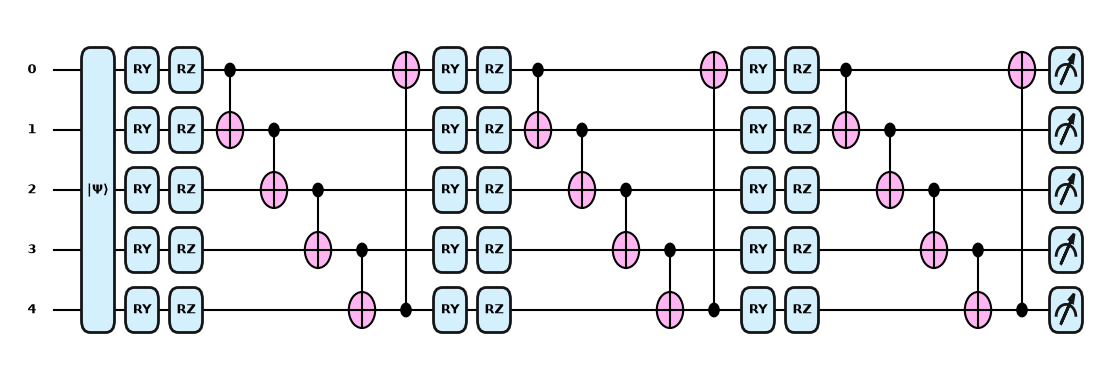

In [8]:
dev5 = qml.device("default.qubit", wires=N_QUBITS)

def ansatz(wy, wz):
    for l in range(N_LAYERS):
        for q in range(N_QUBITS):
            qml.RY(wy[l, q], wires=q); qml.RZ(wz[l, q], wires=q)
        for q in range(N_QUBITS):
            qml.CNOT(wires=[q, (q + 1) % N_QUBITS])          # circular entangling layer

@qml.qnode(dev5)
def partition_circuit(amp, wy, wz):
    qml.StatePrep(amp, wires=range(N_QUBITS), normalize=True)   # amplitude embedding of the 32 (complex) inputs
    ansatz(wy, wz)
    return [qml.expval(qml.PauliZ(q)) for q in range(N_QUBITS)]

demo_amp = np.zeros(32, dtype=complex); demo_amp[:17] = 1 / np.sqrt(17)
try:
    fig, ax = qml.draw_mpl(partition_circuit, style="pennylane", fontsize=9)(demo_amp, np.full((N_LAYERS, N_QUBITS), 0.3), np.full((N_LAYERS, N_QUBITS), 0.6))
    fig.set_size_inches(11, 3.6); plt.show()
except Exception as e:
    print("circuit drawing skipped:", type(e).__name__)
    print(qml.draw(partition_circuit)(demo_amp, np.full((N_LAYERS, N_QUBITS), 0.3), np.full((N_LAYERS, N_QUBITS), 0.6)))

### 3.2 The fast batched implementation used for training

Training needs the circuit for 128 samples, four times, for hundreds of epochs, with gradients. PennyLane's gate-by-gate backpropagation
took about 10 s per epoch on the validation machine for one scenario, i.e. half an hour per scenario for 200 epochs. The circuit is
tiny (32 x 32), so the notebook builds the **same unitary** (product of the `RY`, `RZ` rotations and the `CNOT` ring, in the same order and wire convention) with
differentiable tensor operations once per optimisation step and applies it to the whole batch with one matrix product; the Z expectation is the probability-weighted sign
of each qubit. The next cell implements it and **checks it against the PennyLane circuit** of Section 3.1 on random inputs.

In [9]:
# ---------- batched tensor implementation of the paper's circuit (same gates, same wire order as PennyLane) ----------
def ry_m(a):                                             # a: (...) -> (..., 2, 2) complex128
    c, s = torch.cos(a / 2), torch.sin(a / 2)
    return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2).to(torch.complex128)

def rz_m(a):
    e = torch.exp(-0.5j * a.to(torch.complex128)); z = torch.zeros_like(e)
    return torch.stack([torch.stack([e, z], -1), torch.stack([z, e.conj()], -1)], -2)

def ring_perm(nq):                                       # CNOT(0,1) CNOT(1,2) ... CNOT(nq-1,0) as a permutation matrix
    N = 2 ** nq; M = np.zeros((N, N))
    for s in range(N):
        b = [(s >> (nq - 1 - q)) & 1 for q in range(nq)]          # wire 0 is the most significant bit, as in PennyLane
        for q in range(nq): b[(q + 1) % nq] ^= b[q]
        M[sum(bit << (nq - 1 - q) for q, bit in enumerate(b)), s] = 1
    return torch.tensor(M, dtype=torch.complex128)

def z_signs(nq):                                         # (2^nq, nq): +1 / -1 eigenvalue of Z_q on each basis state
    bits = (np.arange(2 ** nq)[:, None] >> (nq - 1 - np.arange(nq))[None, :]) & 1
    return torch.tensor(1.0 - 2.0 * bits, dtype=torch.float64)

def ansatz_unitaries(wy, wz, ring):
    # wy, wz: (P, L, nq) rotation angles of P independent circuits -> unitaries (P, 2^nq, 2^nq)
    P, L, nq = wy.shape
    g = ry_m(wy) if wz is None else rz_m(wz) @ ry_m(wy)             # RY then RZ on every qubit: (P, L, nq, 2, 2)
    K = g[:, :, 0]
    for q in range(1, nq):
        K = torch.einsum("plab,plcd->placbd", K, g[:, :, q]).reshape(P, L, 2 ** (q + 1), 2 ** (q + 1))   # Kronecker product over the qubits
    U = torch.eye(2 ** nq, dtype=torch.complex128).expand(P, -1, -1)
    for l in range(L):
        U = ring @ K[:, l] @ U
    return U

class PartitionedCircuits(nn.Module):
    """K independent 5-qubit circuits: amplitude embedding -> 3 x (RY RZ + CNOT ring) -> <Z_q> (the paper's PQCs C(1)...C(K))."""
    def __init__(self, n_parts=N_PARTS, nq=N_QUBITS, layers=N_LAYERS, seed=SEED):
        super().__init__()
        g = torch.Generator().manual_seed(seed)
        self.wy = nn.Parameter(torch.rand(n_parts, layers, nq, generator=g) * 2 * np.pi)      # CHOICE: initial angles uniform in [0, 2 pi)
        self.wz = nn.Parameter(torch.rand(n_parts, layers, nq, generator=g) * 2 * np.pi)
        self.register_buffer("ring", ring_perm(nq)); self.register_buffer("zs", z_signs(nq))
    def expectations(self, amp):                                   # amp: (B, K, 2^nq) complex, any norm
        amp = amp / amp.abs().pow(2).sum(2, keepdim=True).sqrt().clamp_min(1e-12)         # amplitude embedding normalises
        psi = torch.einsum("pij,bpj->bpi", ansatz_unitaries(self.wy.double(), self.wz.double(), self.ring), amp)
        return psi.abs().pow(2) @ self.zs                          # (B, K, nq)

def encode_partitions(x, dmin, dmax, use_angle=True):
    # x: (B, 120) MinMax-scaled features -> (B, 4, 32) complex amplitudes (13 phasors + 4 real values + zero padding)
    x = x.double()
    ang = (x[:, ANG_IDX] * (dmax[ANG_IDX] - dmin[ANG_IDX]) + dmin[ANG_IDX]) * ANG_UNIT        # physical angle in radians
    if not use_angle: ang = ang * 0.0                                                             # ablation only: real amplitudes (phase angles dropped)
    phasors = torch.polar(x[:, MAG_IDX], ang)                                                    # |z| = scaled magnitude, arg z = angle
    reals = x[:, REAL_IDX].to(torch.complex128)
    pad = torch.zeros(x.shape[0], len(PARTS), 32 - 13 - 4, dtype=torch.complex128)          # CHOICE: zero padding up to 32 amplitudes
    return torch.cat([phasors, reals, pad], dim=2)

# ---------- equivalence check against the PennyLane circuit ----------
chk_rng = np.random.default_rng(SEED)
pc = PartitionedCircuits()
amps_chk = torch.tensor(chk_rng.normal(size=(12, N_PARTS, 32)) + 1j * chk_rng.normal(size=(12, N_PARTS, 32)), dtype=torch.complex128)
fast = pc.expectations(amps_chk).detach().numpy()
slow = np.array([[np.array(partition_circuit(amps_chk[b, p].numpy(), pc.wy[p].detach().numpy(), pc.wz[p].detach().numpy())) for p in range(N_PARTS)] for b in range(12)])
print("max |fast - PennyLane| over 12 random complex inputs x 4 circuits x 5 qubits:", float(np.abs(fast - slow).max()))
assert np.allclose(fast, slow, atol=1e-9), "fast implementation differs from the PennyLane circuit"

max |fast - PennyLane| over 12 random complex inputs x 4 circuits x 5 qubits: 5.551115123125783e-16


### 3.3 Quantum noise: the depolarizing channel of R-QUPID

R-QUPID inserts the channel `E_p(rho) = (1-p) rho + p I/d` after the ansatz (Lemma 3 of the paper). The Pauli-Z expectation of the
maximally mixed state is zero, so the channel simply multiplies every expectation value by `(1 - p)`. The cell checks this on PennyLane's
mixed-state simulator (with the per-qubit depolarizing channel, whose strength is `3p/4` in PennyLane's convention) and with the
global channel written out as a density matrix. What the channel changes in a real device is the **signal-to-noise ratio**, because
the shot noise of the measurement does not shrink with the signal; the notebook therefore also adds finite-shot sampling noise
(Gaussian approximation of `shots` binary measurements) to the R-QUPID circuits (**CHOICE**, the paper does not simulate shots).

In [10]:
p_chk = 0.2
dev_mixed = qml.device("default.mixed", wires=N_QUBITS)
@qml.qnode(dev_mixed)
def noisy_partition(amp, wy, wz, p):
    qml.StatePrep(amp, wires=range(N_QUBITS), normalize=True)
    ansatz(wy, wz)
    for q in range(N_QUBITS):
        qml.DepolarizingChannel(3 * p / 4, wires=q)        # shrinks the Bloch vector of each qubit by (1 - p)
    return [qml.expval(qml.PauliZ(q)) for q in range(N_QUBITS)]

b0, p0 = 0, 1
noisy = np.array(noisy_partition(amps_chk[b0, p0].numpy(), pc.wy[p0].detach().numpy(), pc.wz[p0].detach().numpy(), p_chk))
print("mixed-state simulation vs (1-p) x noiseless expectation, max difference:", float(np.abs(noisy - (1 - p_chk) * slow[b0, p0]).max()))

# the paper's global channel E_p(rho) = (1-p) rho + p I/d, written as a density matrix
U0 = ansatz_unitaries(pc.wy.double(), pc.wz.double(), pc.ring)[p0].detach().numpy()
a0 = amps_chk[b0, p0].numpy(); a0 = a0 / np.linalg.norm(a0)
rho = np.outer(U0 @ a0, (U0 @ a0).conj()); rho_dep = (1 - p_chk) * rho + p_chk * np.eye(32) / 32
zq = z_signs(N_QUBITS).numpy()
glob = np.array([np.real(np.sum(np.diag(rho_dep) * zq[:, q])) for q in range(N_QUBITS)])
print("global channel vs (1-p) x noiseless expectation, max difference:", float(np.abs(glob - (1 - p_chk) * slow[b0, p0]).max()))

mixed-state simulation vs (1-p) x noiseless expectation, max difference: 9.705867637377352e-08
global channel vs (1-p) x noiseless expectation, max difference: 1.942890293094024e-16


## 4. The QUPID network, the baselines and the training loop

`QUPID` is the pipeline of the paper's Figure 1: scaled features -> four phasor-encoded partitions -> four 5-qubit circuits -> 20
expectation values -> two dense layers -> softmax (inside the cross-entropy loss). With `sigma > 0`, `p_dep > 0` or `shots > 0` the same
class becomes **R-QUPID**: Gaussian noise on the input (the classical mechanism `A`), the depolarizing shrinkage `(1 - p)` after the ansatz and
finite-shot sampling noise on the expectation values. These noises are part of the mechanism, so they are active in training *and* at test time.

The baselines use exactly the same scaled inputs: an MLP with scikit-learn defaults (as in the paper), a random forest, an RBF SVM and the
**HQ-DNN** (two dense layers that produce 6 rotation angles, then a 6-qubit `RY` / `CNOT` variational circuit and a linear read-out; the paper's
description is one sentence long, so widths are a **CHOICE**). A torch copy of the MLP (`TorchMLP`, one hidden layer of 100, like scikit-learn's default) is used in the robustness study, where gradients are needed.
The paper's InceptionNet, MTL-LSTM and FTTransformer are **not re-run** (see the choices table).

In [11]:
class QUPID(nn.Module):
    def __init__(self, dmin, dmax, hidden=HIDDEN, n_classes=6, seed=SEED, sigma=0.0, p_dep=0.0, shots=0, use_angle=True):
        super().__init__()
        self.circuits = PartitionedCircuits(seed=seed)
        self.register_buffer("dmin", torch.tensor(dmin)); self.register_buffer("dmax", torch.tensor(dmax))
        torch.manual_seed(seed)
        # CHOICE: BatchNorm + Linear(20, hidden) + ReLU + Linear(hidden, 6). The paper's F(h) = ReLU(W2 ReLU(W1 h)) has a final ReLU on the logits.
        self.head = nn.Sequential(nn.BatchNorm1d(N_PARTS * N_QUBITS), nn.Linear(N_PARTS * N_QUBITS, hidden), nn.ReLU(), nn.Linear(hidden, n_classes))
        self.sigma, self.p_dep, self.shots, self.use_angle = sigma, p_dep, shots, use_angle
    def features(self, x):
        if self.sigma > 0: x = x + self.sigma * torch.randn_like(x)                 # classical Gaussian mechanism A (R-QUPID)
        h = self.circuits.expectations(encode_partitions(x, self.dmin, self.dmax, self.use_angle))
        if self.p_dep > 0: h = (1 - self.p_dep) * h                                  # depolarizing channel after the ansatz
        if self.shots > 0: h = h + torch.randn_like(h) * ((1 - h ** 2).clamp_min(0) / self.shots).sqrt()   # finite-shot sampling noise
        return h.reshape(x.shape[0], -1).float()
    def forward(self, x):
        return self.head(self.features(x))

class HQDNN(nn.Module):
    """Quantum-classical hybrid DNN baseline: Dense-Dense -> RY angle embedding -> (RY + CNOT ring) x 2 -> <Z> -> Linear."""
    def __init__(self, n_in, nq=6, layers=2, n_classes=6, seed=SEED):
        super().__init__()
        torch.manual_seed(seed); self.nq = nq
        self.pre = nn.Sequential(nn.Linear(n_in, 64), nn.ReLU(), nn.Linear(64, nq))     # CHOICE: widths
        self.wy = nn.Parameter(torch.rand(1, layers, nq) * 2 * np.pi)
        self.post = nn.Linear(nq, n_classes)
        self.register_buffer("ring", ring_perm(nq)); self.register_buffer("zs", z_signs(nq))
    def forward(self, x):
        a = torch.tanh(self.pre(x)) * np.pi
        s = torch.stack([torch.cos(a / 2), torch.sin(a / 2)], -1).to(torch.complex128)         # (B, nq, 2) single-qubit RY states
        st = s[:, 0]
        for q in range(1, self.nq): st = torch.einsum("bi,bj->bij", st, s[:, q]).reshape(x.shape[0], -1)
        psi = st @ ansatz_unitaries(self.wy.double(), None, self.ring)[0].T
        return self.post((psi.abs().pow(2) @ self.zs).float())

class TorchMLP(nn.Module):                                   # same architecture as scikit-learn's default MLPClassifier (one hidden layer of 100)
    def __init__(self, n_in, n_classes=6, seed=SEED):
        super().__init__(); torch.manual_seed(seed)
        self.net = nn.Sequential(nn.Linear(n_in, 100), nn.ReLU(), nn.Linear(100, n_classes))
    def forward(self, x): return self.net(x)

class NoisyInput(nn.Module):                                 # classical Gaussian mechanism A in front of any classical model (always on)
    def __init__(self, model, sigma): super().__init__(); self.model, self.sigma = model, sigma
    def forward(self, x): return self.model(x + self.sigma * torch.randn_like(x) if self.sigma > 0 else x)

def fit_torch(model, Xtr, ytr, epochs, lr=LR, batch=BATCH, seed=SEED, Xmon=None, ymon=None, label="", verbose=True):
    # Adam + cross-entropy, mini-batches of `batch`. Xmon / ymon (the test split) only monitor the curve; nothing is selected with them.
    opt = torch.optim.Adam(model.parameters(), lr=lr); lossf = nn.CrossEntropyLoss()
    Xt, yt = torch.tensor(Xtr, dtype=torch.float32), torch.tensor(ytr)
    gen = torch.Generator().manual_seed(seed); hist = []; t0 = time.time()
    torch.manual_seed(seed)
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xt), generator=gen); tot = 0.0
        for i in range(0, len(Xt), batch):
            idx = perm[i:i + batch]
            if len(idx) < 2: continue
            opt.zero_grad(); loss = lossf(model(Xt[idx]), yt[idx]); loss.backward(); opt.step(); tot += loss.item() * len(idx)
        row = dict(epoch=ep + 1, loss=tot / len(Xt))
        if Xmon is not None and (ep % max(1, epochs // 10) == 0 or ep == epochs - 1):
            row["monitor_acc"] = accuracy_score(ymon, predict_proba_torch(model, Xmon).argmax(1))
        hist.append(row)
        if verbose and (ep % max(1, epochs // 5) == 0 or ep == epochs - 1):
            print(f"  {label} epoch {ep + 1:3d}/{epochs}  loss {row['loss']:.4f}" + (f"  monitor acc {row['monitor_acc']:.3f}" if "monitor_acc" in row else "") + f"  ({time.time() - t0:.0f}s)", flush=True)
    return model, pd.DataFrame(hist), time.time() - t0

def predict_proba_torch(model, X, batch=1024):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), batch):
            out.append(torch.softmax(model(torch.tensor(X[i:i + batch], dtype=torch.float32)), 1).numpy())
    return np.concatenate(out)

### 4.1 The seven metrics

Accuracy, precision, recall and F1 are **class-frequency-weighted** averages (for these the weighted recall equals the accuracy, as in the paper's MLP rows);
ROC-AUC is the one-vs-rest area under the curve averaged with the same weights; MCC is scikit-learn's multi-class Matthews coefficient; G-mean is the weighted
mean over the classes of `sqrt(TPR x TNR)` with the class as the positive label. The paper does not spell the averaging out, so these are **CHOICES**.

In [12]:
METRICS = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC", "MCC", "G-Mean"]

def all_metrics(y, proba, n_classes=6):
    pred = proba.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y, pred, average="weighted", zero_division=0)
    cm = confusion_matrix(y, pred, labels=range(n_classes)); n = cm.sum(); w = cm.sum(1) / n
    tpr = np.diag(cm) / np.maximum(cm.sum(1), 1)
    tnr = (n - cm.sum(0) - cm.sum(1) + np.diag(cm)) / np.maximum(n - cm.sum(1), 1)
    try:
        auc = roc_auc_score(y, proba / proba.sum(1, keepdims=True), multi_class="ovr", average="weighted", labels=list(range(n_classes)))
    except ValueError:
        auc = np.nan
    return {"Accuracy": accuracy_score(y, pred), "Precision": p, "Recall": r, "F1-Score": f, "ROC-AUC": auc,
            "MCC": matthews_corrcoef(y, pred), "G-Mean": float((w * np.sqrt(tpr * tnr)).sum())}

def softmax_np(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

## 5. Train and evaluate on the scenarios (paper, Section V.A and Table I)

For each scenario the cell prepares the split (Section 2), trains QUPID and the five baselines on the same scaled training rows, and
scores the held-out 30 %. QUPID uses the paper's optimiser settings; the scenario loop prints a few progress lines per model. The
"monitor acc" printed during training is the test accuracy and is only displayed, never used to select an epoch or a hyper-parameter:
the number reported is that of the last epoch.

In [13]:
MODELS = ["QUPID", "MLP", "RF", "SVC (RBF)", "HQ-DNN"]
rows, STORE = [], {}

def timed_predict(fn, X):
    t0 = time.time(); P = fn(X); return P, 1000 * (time.time() - t0) / len(X)

def run_scenario(k):
    D = prepare(k); Xtr, Xte, ytr, yte = D["Xtr"], D["Xte"], D["ytr"], D["yte"]
    out = []
    def record(name, proba, fit_s, infer_ms, hist=None, model=None):
        out.append(dict(scenario=k, model=name, **all_metrics(yte, proba), train_s=fit_s, infer_ms=infer_ms))
        STORE[(k, name)] = dict(proba=proba, hist=hist, model=model)
        print(f"  S{k:<2d} {name:<15s} acc {out[-1]['Accuracy']:.3f}  F1 {out[-1]['F1-Score']:.3f}  AUC {out[-1]['ROC-AUC']:.3f}  MCC {out[-1]['MCC']:.3f}  train {fit_s:5.1f}s  infer {infer_ms:.3f} ms/sample", flush=True)
    m, hist, fs = fit_torch(QUPID(D["dmin"], D["dmax"], seed=SEED), Xtr, ytr, EPOCHS, Xmon=Xte, ymon=yte, label=f"S{k} QUPID")
    P, im = timed_predict(lambda X: predict_proba_torch(m, X), Xte); record("QUPID", P, fs, im, hist, m)
    t0 = time.time(); mlp = MLPClassifier(random_state=SEED).fit(Xtr, ytr); fs = time.time() - t0     # scikit-learn defaults, as in the paper
    P, im = timed_predict(mlp.predict_proba, Xte); record("MLP", P, fs, im)
    t0 = time.time(); rf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=2).fit(Xtr, ytr); fs = time.time() - t0
    P, im = timed_predict(rf.predict_proba, Xte); record("RF", P, fs, im)
    t0 = time.time(); svc = SVC(kernel="rbf", decision_function_shape="ovr", random_state=SEED).fit(Xtr, ytr); fs = time.time() - t0
    P, im = timed_predict(lambda X: softmax_np(svc.decision_function(X)), Xte); record("SVC (RBF)", P, fs, im)
    m, hist, fs = fit_torch(HQDNN(Xtr.shape[1]), Xtr, ytr, BASE_EPOCHS, label=f"S{k} HQ-DNN", verbose=False)
    P, im = timed_predict(lambda X: predict_proba_torch(m, X), Xte); record("HQ-DNN", P, fs, im, hist, m)
    return out

for k in SCENARIOS:
    print(f"=== scenario S{k} ===", flush=True)
    rows += run_scenario(k)
RES = pd.DataFrame(rows)
print("done; total time so far: %.1f min" % ((time.time() - T_NOTEBOOK_START) / 60))

=== scenario S1 ===


  S1 QUPID epoch   1/200  loss 1.2810  monitor acc 0.574  (1s)


  S1 QUPID epoch  41/200  loss 0.8590  monitor acc 0.659  (24s)


  S1 QUPID epoch  81/200  loss 0.7557  monitor acc 0.655  (48s)


  S1 QUPID epoch 121/200  loss 0.6817  monitor acc 0.683  (73s)


...

  S15 MLP             acc 0.558  F1 0.526  AUC 0.799  MCC 0.359  train  19.4s  infer 0.005 ms/sample


  S15 RF              acc 0.917  F1 0.916  AUC 0.993  MCC 0.886  train   7.4s  infer 0.160 ms/sample


  S15 SVC (RBF)       acc 0.454  F1 0.315  AUC 0.668  MCC 0.143  train   6.3s  infer 2.051 ms/sample


  S15 HQ-DNN          acc 0.515  F1 0.469  AUC 0.760  MCC 0.288  train  48.0s  infer 0.024 ms/sample


done; total time so far: 52.0 min


### 5.1 Training curve and confusion matrices of the first scenario

The loss of QUPID over the epochs (Adam, learning rate 0.01) and the confusion matrices of QUPID and of the random forest on the same test split. Attacks are classes 3-5.

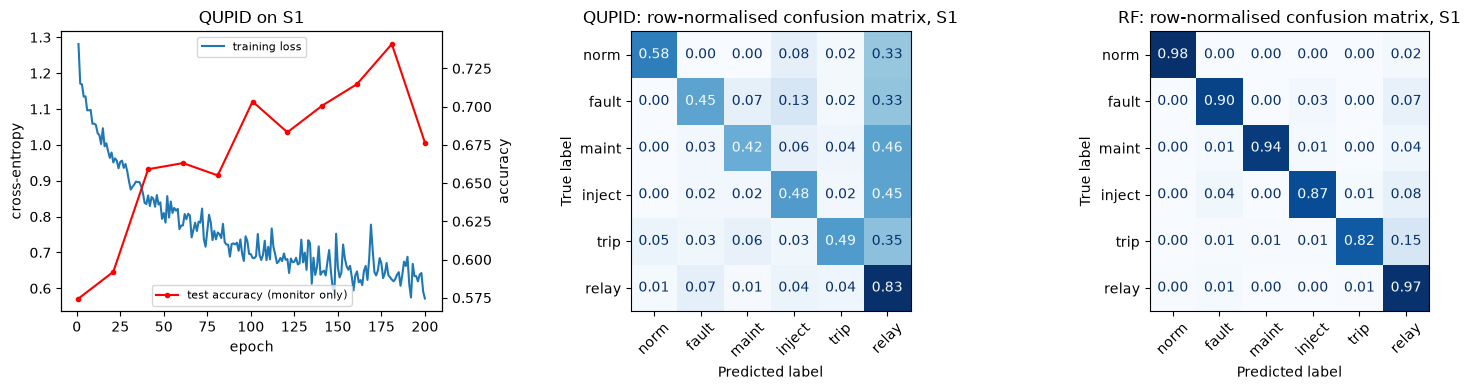

In [14]:
k0 = SCENARIOS[0]
h = STORE[(k0, "QUPID")]["hist"]; yte0 = prepare(k0)["yte"]
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].plot(h["epoch"], h["loss"], label="training loss"); axs[0].set_xlabel("epoch"); axs[0].set_ylabel("cross-entropy")
ax2 = axs[0].twinx(); hm = h.dropna(subset=["monitor_acc"]); ax2.plot(hm["epoch"], hm["monitor_acc"], "r.-", label="test accuracy (monitor only)"); ax2.set_ylabel("accuracy")
axs[0].set_title(f"QUPID on S{k0}"); axs[0].legend(loc="upper center", fontsize=8); ax2.legend(loc="lower center", fontsize=8)
for ax, name in zip(axs[1:], ["QUPID", "RF"]):
    cm = confusion_matrix(yte0, STORE[(k0, name)]["proba"].argmax(1), labels=range(6), normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=["norm", "fault", "maint", "inject", "trip", "relay"]).plot(ax=ax, colorbar=False, cmap="Blues", values_format=".2f")
    ax.set_title(f"{name}: row-normalised confusion matrix, S{k0}"); ax.tick_params(axis="x", labelrotation=45)
plt.tight_layout(); plt.show()

### 5.2 Where does QUPID's accuracy come from? Three small diagnostics on the first scenario

1. A random forest on the **20 expectation values** `h` that the circuits hand to the dense layers: with the trained circuits and with untrained (randomly initialised) ones. If the forest reads the scenario off these 20 numbers, the information survives the amplitude-embedding bottleneck and what limits QUPID is the dense read-out and its optimisation.
2. QUPID with the circuits **frozen** at their random initial angles (only the dense layers train): how much does training the quantum circuit add?
3. QUPID **without the phase angles** (all phasors become real numbers, the angle is set to zero): does the complex-valued encoding, the paper's main selling point, matter?

In [15]:
k0 = SCENARIOS[0]; D0 = prepare(k0)
def h_features(model, X):
    model.eval()
    with torch.no_grad(): return model.features(torch.tensor(X, dtype=torch.float32)).numpy()
def rf_on(Ftr, Fte):
    rf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=2).fit(Ftr, D0["ytr"])
    return all_metrics(D0["yte"], rf.predict_proba(Fte))
diag = {"QUPID (trained circuits + dense head), from Section 5": RES[(RES.scenario == k0) & (RES.model == "QUPID")].iloc[0][METRICS].to_dict(),
        "random forest on the 20 expectation values of the trained circuits": rf_on(h_features(STORE[(k0, "QUPID")]["model"], D0["Xtr"]), h_features(STORE[(k0, "QUPID")]["model"], D0["Xte"]))}
untrained = QUPID(D0["dmin"], D0["dmax"], seed=SEED + 7)
diag["random forest on the 20 expectation values of untrained random circuits"] = rf_on(h_features(untrained, D0["Xtr"]), h_features(untrained, D0["Xte"]))
diag["random forest on the 120 scaled inputs (from Section 5)"] = RES[(RES.scenario == k0) & (RES.model == "RF")].iloc[0][METRICS].to_dict()
frozen = QUPID(D0["dmin"], D0["dmax"], seed=SEED)
for prm in frozen.circuits.parameters(): prm.requires_grad_(False)             # circuits stay at their random initial angles
frozen, _, _ = fit_torch(frozen, D0["Xtr"], D0["ytr"], EPOCHS, label="frozen circuits", verbose=False)
diag["QUPID with frozen random circuits (only the dense layers train)"] = all_metrics(D0["yte"], predict_proba_torch(frozen, D0["Xte"]))
noang, _, _ = fit_torch(QUPID(D0["dmin"], D0["dmax"], seed=SEED, use_angle=False), D0["Xtr"], D0["ytr"], EPOCHS, label="no angles", verbose=False)
diag["QUPID without phase angles (real amplitudes only)"] = all_metrics(D0["yte"], predict_proba_torch(noang, D0["Xte"]))
DIAG = pd.DataFrame(diag).T[METRICS]
print(f"Scenario S{k0}, same split, same training budget ({EPOCHS} epochs):")
display(DIAG.round(3))

Scenario S1, same split, same training budget (200 epochs):


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,MCC,G-Mean
"QUPID (trained circuits + dense head), from Section 5",0.677,0.665,0.677,0.668,0.864,0.462,0.697
random forest on the 20 expectation values of the trained circuits,0.943,0.943,0.943,0.942,0.994,0.909,0.948
random forest on the 20 expectation values of untrained random circuits,0.942,0.943,0.942,0.941,0.994,0.907,0.943
random forest on the 120 scaled inputs (from Section 5),0.936,0.936,0.936,0.935,0.992,0.897,0.941
QUPID with frozen random circuits (only the dense layers train),0.713,0.703,0.713,0.688,0.876,0.508,0.692
QUPID without phase angles (real amplitudes only),0.580,0.547,0.580,0.505,0.762,0.220,0.457


## 6. Table I redrawn: seven metrics per scenario

The tables below have the layout of the paper's Table I (one block per metric, one column per scenario) for QUPID and for the baselines
that we re-ran. The paper's values for the same models are loaded in Section 9 for the side-by-side comparison.

In [16]:
def table(metric, models=MODELS):
    t = RES.pivot(index="model", columns="scenario", values=metric).reindex(models)
    t.columns = [f"S{c}" for c in t.columns]; t["mean"] = t.mean(axis=1)
    return t.round(3)
for mname in METRICS[:4]:
    print(f"--- {mname} ---"); display(table(mname))

--- Accuracy ---


,S1,S2,S3,S4,S5,S6,S7,S8,S9,S10,S11,S12,S13,S14,S15,mean
model,,,,,,,,,,,,,,,,
QUPID,0.677,0.645,0.601,0.661,0.566,0.603,0.658,0.660,0.552,0.547,0.553,0.645,0.743,0.698,0.649,0.630
MLP,0.654,0.560,0.622,0.530,0.520,0.569,0.556,0.550,0.587,0.536,0.582,0.560,0.620,0.614,0.558,0.575
RF,0.936,0.918,0.942,0.928,0.942,0.920,0.931,0.921,0.911,0.935,0.927,0.925,0.927,0.926,0.917,0.927
SVC (RBF),0.589,0.490,0.562,0.460,0.499,0.515,0.502,0.465,0.491,0.506,0.534,0.485,0.570,0.524,0.454,0.510
HQ-DNN,0.579,0.499,0.594,0.487,0.513,0.526,0.525,0.501,0.511,0.527,0.550,0.503,0.598,0.589,0.515,0.534


--- Precision ---


,S1,S2,S3,S4,S5,S6,S7,S8,S9,S10,S11,S12,S13,S14,S15,mean
model,,,,,,,,,,,,,,,,
QUPID,0.665,0.644,0.591,0.665,0.575,0.622,0.655,0.661,0.603,0.598,0.621,0.684,0.738,0.689,0.656,0.644
MLP,0.619,0.532,0.598,0.508,0.500,0.561,0.541,0.547,0.579,0.503,0.563,0.549,0.575,0.613,0.542,0.555
RF,0.936,0.918,0.942,0.929,0.942,0.921,0.931,0.922,0.911,0.936,0.927,0.926,0.929,0.927,0.918,0.927
SVC (RBF),0.554,0.422,0.553,0.418,0.570,0.580,0.468,0.466,0.539,0.501,0.543,0.490,0.482,0.434,0.494,0.501
HQ-DNN,0.466,0.500,0.524,0.467,0.478,0.508,0.496,0.495,0.493,0.464,0.504,0.496,0.536,0.558,0.470,0.497


--- Recall ---


,S1,S2,S3,S4,S5,S6,S7,S8,S9,S10,S11,S12,S13,S14,S15,mean
model,,,,,,,,,,,,,,,,
QUPID,0.677,0.645,0.601,0.661,0.566,0.603,0.658,0.660,0.552,0.547,0.553,0.645,0.743,0.698,0.649,0.630
MLP,0.654,0.560,0.622,0.530,0.520,0.569,0.556,0.550,0.587,0.536,0.582,0.560,0.620,0.614,0.558,0.575
RF,0.936,0.918,0.942,0.928,0.942,0.920,0.931,0.921,0.911,0.935,0.927,0.925,0.927,0.926,0.917,0.927
SVC (RBF),0.589,0.490,0.562,0.460,0.499,0.515,0.502,0.465,0.491,0.506,0.534,0.485,0.570,0.524,0.454,0.510
HQ-DNN,0.579,0.499,0.594,0.487,0.513,0.526,0.525,0.501,0.511,0.527,0.550,0.503,0.598,0.589,0.515,0.534


--- F1-Score ---


,S1,S2,S3,S4,S5,S6,S7,S8,S9,S10,S11,S12,S13,S14,S15,mean
model,,,,,,,,,,,,,,,,
QUPID,0.668,0.639,0.585,0.654,0.568,0.607,0.634,0.657,0.539,0.554,0.565,0.623,0.730,0.686,0.624,0.622
MLP,0.603,0.517,0.575,0.493,0.471,0.518,0.499,0.498,0.553,0.499,0.543,0.514,0.554,0.573,0.526,0.529
RF,0.935,0.917,0.941,0.928,0.942,0.919,0.930,0.920,0.910,0.935,0.926,0.925,0.926,0.926,0.916,0.926
SVC (RBF),0.470,0.357,0.431,0.339,0.390,0.390,0.369,0.330,0.392,0.374,0.416,0.391,0.434,0.396,0.315,0.386
HQ-DNN,0.496,0.448,0.521,0.390,0.450,0.453,0.400,0.411,0.471,0.475,0.471,0.455,0.507,0.540,0.469,0.464


In [17]:
for mname in METRICS[4:]:
    print(f"--- {mname} ---"); display(table(mname))
summary = RES.groupby("model")[METRICS + ["train_s", "infer_ms"]].agg(["mean", "std"]).reindex(MODELS)
print("mean and standard deviation over the scenarios run:")
display(summary[[(m, s) for m in METRICS for s in ("mean", "std")]].round(3))

--- ROC-AUC ---


,S1,S2,S3,S4,S5,S6,S7,S8,S9,S10,S11,S12,S13,S14,S15,mean
model,,,,,,,,,,,,,,,,
QUPID,0.864,0.870,0.821,0.878,0.833,0.837,0.874,0.878,0.840,0.840,0.833,0.875,0.890,0.880,0.894,0.860
MLP,0.826,0.789,0.811,0.780,0.784,0.778,0.774,0.811,0.825,0.786,0.807,0.795,0.795,0.801,0.799,0.797
RF,0.992,0.992,0.994,0.992,0.994,0.991,0.992,0.992,0.990,0.994,0.994,0.991,0.992,0.993,0.993,0.992
SVC (RBF),0.646,0.624,0.643,0.650,0.649,0.628,0.594,0.657,0.683,0.682,0.598,0.695,0.610,0.673,0.668,0.647
HQ-DNN,0.717,0.725,0.756,0.702,0.740,0.712,0.707,0.732,0.770,0.753,0.758,0.746,0.761,0.785,0.760,0.742


--- MCC ---


,S1,S2,S3,S4,S5,S6,S7,S8,S9,S10,S11,S12,S13,S14,S15,mean
model,,,,,,,,,,,,,,,,
QUPID,0.462,0.503,0.374,0.529,0.407,0.440,0.483,0.526,0.384,0.406,0.414,0.509,0.577,0.541,0.519,0.472
MLP,0.380,0.343,0.358,0.316,0.281,0.304,0.302,0.343,0.402,0.282,0.336,0.377,0.324,0.384,0.359,0.339
RF,0.897,0.885,0.910,0.902,0.919,0.883,0.900,0.891,0.876,0.908,0.893,0.898,0.885,0.891,0.886,0.895
SVC (RBF),0.161,0.149,0.189,0.167,0.219,0.153,0.135,0.165,0.206,0.164,0.209,0.235,0.147,0.151,0.143,0.173
HQ-DNN,0.196,0.233,0.287,0.218,0.258,0.214,0.227,0.249,0.286,0.259,0.255,0.290,0.261,0.335,0.288,0.257


--- G-Mean ---


,S1,S2,S3,S4,S5,S6,S7,S8,S9,S10,S11,S12,S13,S14,S15,mean
model,,,,,,,,,,,,,,,,
QUPID,0.697,0.734,0.646,0.737,0.686,0.708,0.682,0.742,0.660,0.680,0.692,0.704,0.745,0.741,0.719,0.705
MLP,0.580,0.585,0.561,0.578,0.534,0.542,0.528,0.558,0.630,0.560,0.574,0.588,0.521,0.602,0.607,0.570
RF,0.941,0.937,0.947,0.948,0.958,0.935,0.947,0.942,0.933,0.948,0.941,0.944,0.929,0.945,0.938,0.942
SVC (RBF),0.276,0.259,0.254,0.312,0.361,0.284,0.246,0.258,0.395,0.285,0.312,0.426,0.235,0.284,0.247,0.296
HQ-DNN,0.416,0.516,0.465,0.398,0.511,0.459,0.352,0.450,0.570,0.522,0.462,0.559,0.415,0.568,0.551,0.481


mean and standard deviation over the scenarios run:

Accuracy        Precision        Recall        F1-Score        ROC-AUC           MCC        G-Mean       
              mean    std      mean    std   mean    std     mean    std    mean    std   mean    std   mean    std
model                                                                                                              
QUPID        0.630  0.058     0.644  0.043  0.630  0.058    0.622  0.053   0.860  0.024  0.472  0.064  0.705  0.031
MLP          0.575  0.038     0.555  0.037  0.575  0.038    0.529  0.037   0.797  0.016  0.339  0.038  0.570  0.031
RF           0.927  0.009     0.927  0.009  0.927  0.009    0.926  0.009   0.992  0.001  0.895  0.012  0.942  0.007
SVC (RBF)    0.510  0.040     0.501  0.054  0.510  0.040    0.386  0.042   0.647  0.031  0.173  0.031  0.296  0.057
HQ-DNN       0.534  0.038     0.497  0.027  0.534  0.038    0.464  0.042   0.742  0.025  0.257  0.036  0.481  0.068

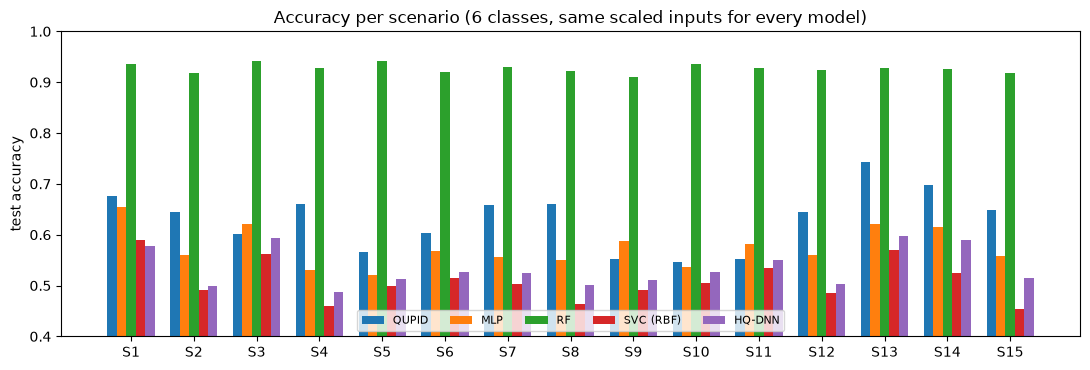

QUPID on S1, 3 initialisation seeds (same split):


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,MCC,G-Mean
mean,0.718,0.706,0.718,0.708,0.883,0.530,0.733
std,0.043,0.046,0.043,0.044,0.018,0.072,0.039


In [18]:
fig, ax = plt.subplots(figsize=(11, 3.8)); wd = 0.15
acc = RES.pivot(index="scenario", columns="model", values="Accuracy")[MODELS]
for i, mname in enumerate(MODELS):
    ax.bar(np.arange(len(acc)) + (i - 2) * wd, acc[mname], wd, label=mname)
ax.set_xticks(range(len(acc))); ax.set_xticklabels([f"S{s}" for s in acc.index]); ax.set_ylim(0.4, 1.0)
ax.set_ylabel("test accuracy"); ax.set_title("Accuracy per scenario (6 classes, same scaled inputs for every model)"); ax.legend(ncol=5, fontsize=8, loc="lower center")
plt.tight_layout(); plt.show()

if SEED_REPEATS > 1:
    reps = []
    D = prepare(SCENARIOS[0])
    for r in range(SEED_REPEATS):
        m, _, _ = fit_torch(QUPID(D["dmin"], D["dmax"], seed=SEED + r), D["Xtr"], D["ytr"], EPOCHS, label=f"seed {SEED + r}", verbose=False)
        reps.append(all_metrics(D["yte"], predict_proba_torch(m, D["Xte"])))
    rep = pd.DataFrame(reps)[METRICS]
    print(f"QUPID on S{SCENARIOS[0]}, {SEED_REPEATS} initialisation seeds (same split):"); display(rep.agg(["mean", "std"]).round(3))

## 7. Robustness study: FGSM and PGD against QUPID, R-QUPID and noisy classical baselines (paper, Section V.B and Figure 3)

**Attacks.** FGSM moves every input by `eps` in the direction of the sign of the loss gradient; PGD repeats smaller steps (`eps / 4`, from a
random start) and projects back into the L-infinity ball of radius `eps` and into [0, 1]. Both are *white-box* attacks on the model as deployed (including its noise: one noise
draw per gradient), crafted on the MinMax-scaled inputs, which is the common space of all models. The attack bounds are the paper's 0.05 and 0.1.

**Defences compared.** Plain QUPID; **R-QUPID** = QUPID with input Gaussian noise `sigma`, depolarizing shrinkage `(1 - p)` and finite-shot sampling noise (Section 3.3);
the MLP with Gaussian input noise of the same `sigma` (the paper's "classical noise"). Noise is active during training and during testing.
The paper picks "the most optimal performance of R-QUPID" over its noise settings; this notebook reports every setting and the best one.
All of this is on one scenario (the paper does not say which) and the test samples are the first `ROBUST_TEST_N` test rows.

In [19]:
def craft(model, X, y, eps, method, steps=PGD_STEPS, chunk=256):
    model.eval(); lossf = nn.CrossEntropyLoss(); out = []
    gen = torch.Generator().manual_seed(SEED)
    for i in range(0, len(X), chunk):
        x0 = torch.tensor(X[i:i + chunk], dtype=torch.float32); yt = torch.tensor(y[i:i + chunk])
        if method == "fgsm":
            x = x0.clone().requires_grad_(True)
            g, = torch.autograd.grad(lossf(model(x), yt), x)
            adv = (x0 + eps * g.sign()).clamp(0, 1)
        else:
            x = (x0 + (torch.rand(x0.shape, generator=gen) * 2 - 1) * eps).clamp(0, 1)
            for _ in range(steps):
                x.requires_grad_(True)
                g, = torch.autograd.grad(lossf(model(x), yt), x)
                x = x.detach() + (eps / 4) * g.sign()
                x = torch.min(torch.max(x, x0 - eps), x0 + eps).clamp(0, 1)
            adv = x
        out.append(adv.detach().numpy())
    return np.concatenate(out)

def accuracy_of(model, X, y):
    return accuracy_score(y, predict_proba_torch(model, X).argmax(1))

DR = prepare(ROBUST_SCENARIO)
Xr_tr, yr_tr = DR["Xtr"], DR["ytr"]
Xr_te, yr_te = DR["Xte"][:ROBUST_TEST_N], DR["yte"][:ROBUST_TEST_N]
configs = []   # (label, family, builder)
for sg in NOISE_SIGMAS:
    for pd_ in DEPOL_P:
        if sg == 0 and pd_ == 0: configs.append(("QUPID", "QUPID", lambda: QUPID(DR["dmin"], DR["dmax"])))
        else: configs.append((f"R-QUPID s={sg} p={pd_}", "R-QUPID", lambda sg=sg, pd_=pd_: QUPID(DR["dmin"], DR["dmax"], sigma=sg, p_dep=pd_, shots=SHOTS)))
for sg in NOISE_SIGMAS:
    configs.append((f"MLP s={sg}", "MLP", lambda sg=sg: NoisyInput(TorchMLP(Xr_tr.shape[1]), sg)))

rob_rows = []
for label, fam, build in configs:
    m, _, fs = fit_torch(build(), Xr_tr, yr_tr, ROBUST_EPOCHS, label=label, verbose=False)
    r = dict(model=label, family=fam, clean=accuracy_of(m, Xr_te, yr_te))
    for eps in ATTACK_EPS:
        for method in ("fgsm", "pgd"):
            r[f"{method}@{eps}"] = accuracy_of(m, craft(m, Xr_te, yr_te, eps, method), yr_te)
    rob_rows.append(r)
    print(f"  {label:<26s} clean {r['clean']:.3f}  " + "  ".join(f"{k} {v:.3f}" for k, v in r.items() if "@" in k) + f"   ({fs:.0f}s)", flush=True)
ROB = pd.DataFrame(rob_rows)
display(ROB.round(3))

  QUPID                      clean 0.743  fgsm@0.05 0.368  pgd@0.05 0.006  fgsm@0.1 0.443  pgd@0.1 0.001   (71s)


  R-QUPID s=0.0 p=0.2        clean 0.624  fgsm@0.05 0.402  pgd@0.05 0.081  fgsm@0.1 0.378  pgd@0.1 0.039   (75s)


  R-QUPID s=0.02 p=0.0       clean 0.615  fgsm@0.05 0.383  pgd@0.05 0.108  fgsm@0.1 0.420  pgd@0.1 0.056   (77s)


  R-QUPID s=0.02 p=0.2       clean 0.606  fgsm@0.05 0.389  pgd@0.05 0.163  fgsm@0.1 0.391  pgd@0.1 0.064   (77s)


  R-QUPID s=0.05 p=0.0       clean 0.590  fgsm@0.05 0.440  pgd@0.05 0.335  fgsm@0.1 0.377  pgd@0.1 0.135   (58s)


  R-QUPID s=0.05 p=0.2       clean 0.593  fgsm@0.05 0.480  pgd@0.05 0.364  fgsm@0.1 0.431  pgd@0.1 0.205   (54s)


  MLP s=0.0                  clean 0.618  fgsm@0.05 0.053  pgd@0.05 0.023  fgsm@0.1 0.013  pgd@0.1 0.007   (12s)


  MLP s=0.02                 clean 0.603  fgsm@0.05 0.123  pgd@0.05 0.061  fgsm@0.1 0.051  pgd@0.1 0.015   (12s)


  MLP s=0.05                 clean 0.606  fgsm@0.05 0.222  pgd@0.05 0.156  fgsm@0.1 0.172  pgd@0.1 0.063   (14s)


,model,family,clean,fgsm@0.05,pgd@0.05,fgsm@0.1,pgd@0.1
0,QUPID,QUPID,0.743,0.368,0.006,0.443,0.001
1,R-QUPID s=0.0 p=0.2,R-QUPID,0.624,0.402,0.081,0.378,0.039
2,R-QUPID s=0.02 p=0.0,R-QUPID,0.615,0.383,0.108,0.420,0.056
3,R-QUPID s=0.02 p=0.2,R-QUPID,0.606,0.389,0.163,0.391,0.064
4,R-QUPID s=0.05 p=0.0,R-QUPID,0.590,0.440,0.335,0.377,0.135
5,R-QUPID s=0.05 p=0.2,R-QUPID,0.593,0.480,0.364,0.431,0.205
6,MLP s=0.0,MLP,0.618,0.053,0.023,0.013,0.007
7,MLP s=0.02,MLP,0.603,0.123,0.061,0.051,0.015
8,MLP s=0.05,MLP,0.606,0.222,0.156,0.172,0.063


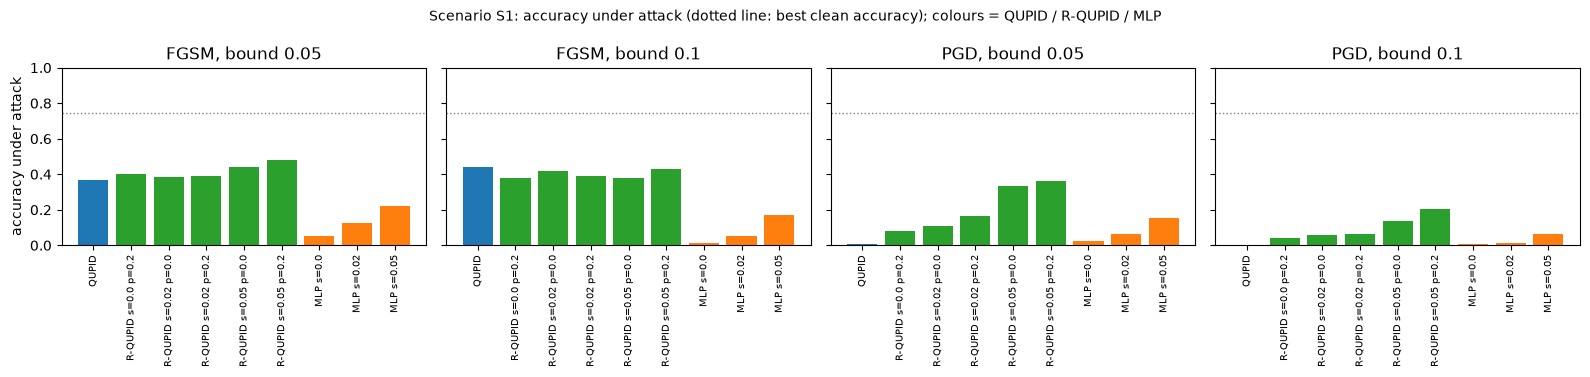

In [20]:
fig, axs = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
colors = {"QUPID": "tab:blue", "R-QUPID": "tab:green", "MLP": "tab:orange"}
for ax, (method, eps) in zip(axs, [(m, e) for m in ("fgsm", "pgd") for e in ATTACK_EPS]):
    ax.bar(range(len(ROB)), ROB[f"{method}@{eps}"], color=[colors[f] for f in ROB["family"]])
    ax.axhline(ROB["clean"].max(), color="gray", ls=":", lw=1)
    ax.set_xticks(range(len(ROB))); ax.set_xticklabels(ROB["model"], rotation=90, fontsize=7)
    ax.set_title(f"{method.upper()}, bound {eps}"); ax.set_ylim(0, 1)
axs[0].set_ylabel("accuracy under attack")
plt.suptitle(f"Scenario S{ROBUST_SCENARIO}: accuracy under attack (dotted line: best clean accuracy); colours = QUPID / R-QUPID / MLP", fontsize=10)
plt.tight_layout(); plt.show()

## 8. Paper versus this notebook

**Table I.** The paper's values for the models we re-implemented (QUPID, MLP, HQ-DNN; InceptionNet, MTL-LSTM and FTTransformer are not re-run) are compared, metric by metric, with
the mean of our runs over the same scenarios. The verdict is **reproduced** when our mean is within 0.02 of the paper's, **exceeded** when it is more than 0.02
above and **not reached** when it is more than 0.02 below. The names differ on purpose: our "MLP" is scikit-learn's default as in the paper, but our "HQ-DNN" is a
compact stand-in written from a one-sentence description, so its row tests the idea rather than the original network.

In [21]:
PAPER_T1 = json.loads(r"""{"Accuracy": {"MLP": [0.854, 0.776, 0.849, 0.809, 0.782, 0.812, 0.829, 0.845, 0.82, 0.805, 0.824, 0.816, 0.85, 0.838, 0.807], "InceptionNet": [0.817, 0.782, 0.8, 0.738, 0.743, 0.773, 0.801, 0.778, 0.767, 0.79, 0.781, 0.818, 0.784, 0.808, 0.805], "MTL-LSTM": [0.869, 0.864, 0.875, 0.825, 0.864, 0.871, 0.864, 0.865, 0.84, 0.853, 0.871, 0.861, 0.885, 0.861, 0.852], "HQ-DNN": [0.823, 0.796, 0.824, 0.794, 0.771, 0.795, 0.782, 0.761, 0.815, 0.8, 0.808, 0.798, 0.783, 0.808, 0.789], "FTTransformer": [0.921, 0.911, 0.908, 0.919, 0.892, 0.923, 0.908, 0.932, 0.9, 0.934, 0.912, 0.926, 0.915, 0.927, 0.914], "QUPID (Ours)": [0.94, 0.893, 0.926, 0.93, 0.89, 0.918, 0.94, 0.92, 0.89, 0.914, 0.943, 0.927, 0.903, 0.941, 0.929]}, "Precision": {"MLP": [0.851, 0.78, 0.849, 0.808, 0.778, 0.81, 0.826, 0.845, 0.821, 0.804, 0.825, 0.814, 0.851, 0.835, 0.802], "InceptionNet": [0.757, 0.74, 0.777, 0.703, 0.692, 0.719, 0.754, 0.747, 0.707, 0.738, 0.738, 0.785, 0.76, 0.753, 0.775], "MTL-LSTM": [0.829, 0.848, 0.839, 0.785, 0.851, 0.846, 0.846, 0.853, 0.819, 0.82, 0.856, 0.842, 0.849, 0.837, 0.821], "HQ-DNN": [0.824, 0.798, 0.871, 0.827, 0.809, 0.802, 0.771, 0.814, 0.801, 0.773, 0.811, 0.81, 0.765, 0.83, 0.769], "FTTransformer": [0.9, 0.888, 0.872, 0.907, 0.871, 0.91, 0.893, 0.928, 0.89, 0.921, 0.892, 0.899, 0.916, 0.925, 0.895], "QUPID (Ours)": [0.933, 0.882, 0.894, 0.928, 0.872, 0.902, 0.895, 0.921, 0.863, 0.915, 0.935, 0.928, 0.916, 0.923, 0.919]}, "Recall": {"MLP": [0.854, 0.776, 0.849, 0.809, 0.782, 0.812, 0.829, 0.845, 0.82, 0.805, 0.824, 0.816, 0.85, 0.838, 0.807], "InceptionNet": [0.735, 0.724, 0.713, 0.704, 0.672, 0.721, 0.746, 0.774, 0.679, 0.763, 0.746, 0.777, 0.743, 0.764, 0.769], "MTL-LSTM": [0.815, 0.842, 0.853, 0.801, 0.838, 0.833, 0.833, 0.875, 0.825, 0.832, 0.846, 0.825, 0.869, 0.86, 0.82], "HQ-DNN": [0.686, 0.678, 0.685, 0.707, 0.707, 0.679, 0.667, 0.673, 0.696, 0.71, 0.691, 0.691, 0.613, 0.645, 0.652], "FTTransformer": [0.888, 0.886, 0.883, 0.908, 0.871, 0.909, 0.889, 0.918, 0.864, 0.921, 0.899, 0.898, 0.906, 0.906, 0.892], "QUPID (Ours)": [0.899, 0.89, 0.901, 0.915, 0.873, 0.892, 0.898, 0.892, 0.849, 0.898, 0.938, 0.92, 0.882, 0.935, 0.918]}, "F1-Score": {"MLP": [0.851, 0.777, 0.848, 0.808, 0.778, 0.81, 0.826, 0.845, 0.819, 0.804, 0.823, 0.814, 0.85, 0.836, 0.803], "InceptionNet": [0.744, 0.727, 0.74, 0.697, 0.678, 0.714, 0.749, 0.757, 0.69, 0.75, 0.733, 0.779, 0.745, 0.758, 0.771], "MTL-LSTM": [0.821, 0.844, 0.845, 0.792, 0.843, 0.839, 0.838, 0.864, 0.821, 0.826, 0.851, 0.833, 0.858, 0.848, 0.82], "HQ-DNN": [0.712, 0.724, 0.744, 0.742, 0.741, 0.722, 0.696, 0.722, 0.727, 0.737, 0.735, 0.727, 0.649, 0.704, 0.68], "FTTransformer": [0.894, 0.886, 0.877, 0.907, 0.871, 0.909, 0.89, 0.923, 0.875, 0.92, 0.895, 0.898, 0.91, 0.915, 0.893], "QUPID (Ours)": [0.925, 0.886, 0.897, 0.925, 0.872, 0.896, 0.896, 0.905, 0.855, 0.906, 0.937, 0.921, 0.897, 0.928, 0.918]}, "ROC-AUC": {"MLP": [0.94, 0.923, 0.956, 0.937, 0.93, 0.929, 0.946, 0.954, 0.93, 0.934, 0.937, 0.924, 0.937, 0.942, 0.928], "InceptionNet": [0.92, 0.896, 0.9, 0.903, 0.89, 0.918, 0.898, 0.907, 0.9, 0.918, 0.916, 0.915, 0.911, 0.906, 0.913], "MTL-LSTM": [0.945, 0.963, 0.963, 0.958, 0.954, 0.959, 0.958, 0.973, 0.957, 0.967, 0.964, 0.96, 0.964, 0.971, 0.959], "HQ-DNN": [0.926, 0.917, 0.927, 0.924, 0.944, 0.922, 0.914, 0.92, 0.923, 0.928, 0.928, 0.928, 0.91, 0.911, 0.923], "FTTransformer": [0.972, 0.972, 0.973, 0.977, 0.964, 0.973, 0.972, 0.976, 0.972, 0.978, 0.977, 0.976, 0.97, 0.976, 0.976], "QUPID (Ours)": [0.975, 0.966, 0.974, 0.973, 0.965, 0.979, 0.97, 0.964, 0.971, 0.983, 0.977, 0.98, 0.967, 0.978, 0.97]}, "MCC": {"MLP": [0.763, 0.691, 0.77, 0.737, 0.694, 0.725, 0.752, 0.789, 0.753, 0.723, 0.745, 0.75, 0.767, 0.76, 0.734], "InceptionNet": [0.702, 0.691, 0.692, 0.641, 0.639, 0.674, 0.713, 0.705, 0.678, 0.708, 0.683, 0.754, 0.662, 0.716, 0.736], "MTL-LSTM": [0.789, 0.81, 0.81, 0.762, 0.812, 0.812, 0.805, 0.817, 0.781, 0.792, 0.812, 0.811, 0.821, 0.799, 0.797], "HQ-DNN": [0.708, 0.706, 0.727, 0.715, 0.675, 0.686, 0.677, 0.666, 0.743, 0.712, 0.712, 0.724, 0.654, 0.707, 0.71], "FTTransformer": [0.874, 0.875, 0.863, 0.889, 0.851, 0.886, 0.868, 0.907, 0.863, 0.906, 0.871, 0.901, 0.869, 0.891, 0.883], "QUPID (Ours)": [0.904, 0.851, 0.889, 0.904, 0.846, 0.878, 0.871, 0.89, 0.849, 0.878, 0.917, 0.901, 0.849, 0.912, 0.904]}, "G-Mean": {"MLP": [0.875, 0.846, 0.887, 0.866, 0.843, 0.861, 0.873, 0.896, 0.878, 0.864, 0.873, 0.872, 0.888, 0.882, 0.865], "InceptionNet": [0.835, 0.829, 0.821, 0.813, 0.795, 0.828, 0.844, 0.858, 0.801, 0.853, 0.841, 0.863, 0.837, 0.855, 0.858], "MTL-LSTM": [0.887, 0.903, 0.909, 0.877, 0.901, 0.899, 0.898, 0.921, 0.891, 0.897, 0.906, 0.894, 0.919, 0.913, 0.89], "HQ-DNN": [0.806, 0.8, 0.806, 0.819, 0.816, 0.8, 0.792, 0.795, 0.816, 0.822, 0.809, 0.811, 0.757, 0.782, 0.787], "FTTransformer": [0.933, 0.932, 0.929, 0.944, 0.922, 0.945, 0.933, 0.951, 0.919, 0.952, 0.938, 0.94, 0.941, 0.943, 0.935], "QUPID (Ours)": [0.94, 0.931, 0.94, 0.949, 0.922, 0.935, 0.938, 0.936, 0.91, 0.937, 0.962, 0.951, 0.926, 0.96, 0.95]}}""")      # Table I of the paper: metric -> model -> [S1 ... S15], parsed from the paper's text
PAPER_NAME = {"QUPID": "QUPID (Ours)", "MLP": "MLP", "HQ-DNN": "HQ-DNN"}
TOL = 0.02
def verdict(paper, ours, tol=TOL):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)): return "cannot be checked"
    if abs(ours - paper) <= tol: return "reproduced"
    return "exceeded" if ours > paper else "not reached"

idx = [s - 1 for s in SCENARIOS]
rows_t1 = []
for ours_name, paper_name in PAPER_NAME.items():
    for mt in METRICS:
        pv = float(np.mean([PAPER_T1[mt][paper_name][i] for i in idx]))
        ov = float(RES[RES.model == ours_name][mt].mean())
        rows_t1.append(dict(model=ours_name, metric=mt, paper_mean=round(pv, 3), notebook_mean=round(ov, 3), gap=round(ov - pv, 3), verdict=verdict(pv, ov)))
T1 = pd.DataFrame(rows_t1)
display(T1.pivot(index="model", columns="metric", values="verdict")[METRICS].reindex(list(PAPER_NAME)))
display(T1.pivot(index="model", columns="metric", values="gap")[METRICS].reindex(list(PAPER_NAME)))
print("paper QUPID accuracy per scenario vs ours:")
display(pd.DataFrame({"paper": [PAPER_T1["Accuracy"]["QUPID (Ours)"][i] for i in idx],
                      "notebook": RES[RES.model == "QUPID"].set_index("scenario")["Accuracy"].round(3).values},
                     index=[f"S{s}" for s in SCENARIOS]).T)

metric,Accuracy,Precision,Recall,F1-Score,ROC-AUC,MCC,G-Mean
model,,,,,,,
QUPID,not reached,not reached,not reached,not reached,not reached,not reached,not reached
MLP,not reached,not reached,not reached,not reached,not reached,not reached,not reached
HQ-DNN,not reached,not reached,not reached,not reached,not reached,not reached,not reached


metric,Accuracy,Precision,Recall,F1-Score,ROC-AUC,MCC,G-Mean
model,,,,,,,
QUPID,-0.290,-0.264,-0.270,-0.282,-0.112,-0.411,-0.234
MLP,-0.246,-0.265,-0.246,-0.290,-0.139,-0.404,-0.301
HQ-DNN,-0.262,-0.308,-0.144,-0.254,-0.181,-0.444,-0.320


paper QUPID accuracy per scenario vs ours:


,S1,S2,S3,S4,S5,S6,S7,S8,S9,S10,S11,S12,S13,S14,S15
paper,0.940,0.893,0.926,0.930,0.890,0.918,0.940,0.92,0.890,0.914,0.943,0.927,0.903,0.941,0.929
notebook,0.677,0.645,0.601,0.661,0.566,0.603,0.658,0.66,0.552,0.547,0.553,0.645,0.743,0.698,0.649


In [22]:
# ---- ranking claims of Section V.A, checked on the paper's own table and on ours ----
q = "QUPID (Ours)"; paper_others = [m for m in PAPER_T1["Accuracy"] if m != q]
def best_counts_paper(models, scen):
    return {mt: sum(all(PAPER_T1[mt][q][s - 1] >= PAPER_T1[mt][o][s - 1] for o in models) for s in scen) for mt in METRICS}
def best_counts_ours(models, scen):
    piv = {mt: RES.pivot(index="scenario", columns="model", values=mt) for mt in METRICS}
    return {mt: int(sum(all(piv[mt].loc[s, "QUPID"] >= piv[mt].loc[s, o] for o in models) for s in scen)) for mt in METRICS}
n_run = len(SCENARIOS)
print(f"Scenarios in which QUPID is >= every baseline, per metric (paper's Table I: all five baselines, 15 scenarios):")
cmp_rank = pd.DataFrame({"paper (15 scen.)": best_counts_paper(paper_others, range(1, 16)),
                         f"paper (same {n_run} scen.)": best_counts_paper(paper_others, SCENARIOS),
                         "notebook vs MLP, HQ-DNN": best_counts_ours(["MLP", "HQ-DNN"], SCENARIOS),
                         "notebook vs MLP, HQ-DNN, RF, SVC": best_counts_ours(["MLP", "RF", "SVC (RBF)", "HQ-DNN"], SCENARIOS)}).T
display(cmp_rank)
dom_paper = [s for s in range(1, 16) if all(all(PAPER_T1[mt][q][s - 1] >= PAPER_T1[mt][o][s - 1] for o in paper_others) for mt in METRICS)]
print("scenarios where QUPID is >= all baselines on all seven metrics in the paper's table:", dom_paper, "(the paper names S1, S3, S11, S12)")

Scenarios in which QUPID is >= every baseline, per metric (paper's Table I: all five baselines, 15 scenarios):


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,MCC,G-Mean
paper (15 scen.),8,9,10,10,8,8,9
paper (same 15 scen.),8,9,10,10,8,8,9
"notebook vs MLP, HQ-DNN",12,14,12,14,15,14,15
"notebook vs MLP, HQ-DNN, RF, SVC",0,0,0,0,0,0,0


scenarios where QUPID is >= all baselines on all seven metrics in the paper's table: [1, 3, 11, 12] (the paper names S1, S3, S11, S12)


In [23]:
# ---- is Table I internally consistent? weighted recall equals accuracy by definition, so the gap |accuracy - recall| shows which averaging each row used ----
cons = pd.DataFrame({m: dict(mean_accuracy=np.mean(PAPER_T1["Accuracy"][m]), mean_recall=np.mean(PAPER_T1["Recall"][m]),
                             max_abs_gap=np.max(np.abs(np.array(PAPER_T1["Accuracy"][m]) - np.array(PAPER_T1["Recall"][m])))) for m in PAPER_T1["Accuracy"]}).T
print("paper's Table I: accuracy versus recall per model (weighted-average recall would equal accuracy):")
display(cons.round(3))

paper's Table I: accuracy versus recall per model (weighted-average recall would equal accuracy):


,mean_accuracy,mean_recall,max_abs_gap
MLP,0.821,0.821,0.000
InceptionNet,0.786,0.735,0.088
MTL-LSTM,0.861,0.838,0.054
HQ-DNN,0.796,0.679,0.170
FTTransformer,0.916,0.896,0.036
QUPID (Ours),0.920,0.900,0.042


In [24]:
# ---- final scoreboard: one line per claim ----
claims = []
def add(claim, paper, ours, verdict_text):
    claims.append(dict(claim=claim, paper=paper, notebook=ours, verdict=verdict_text))

for mt in ("Accuracy", "F1-Score", "ROC-AUC"):
    r = T1[(T1.model == "QUPID") & (T1.metric == mt)].iloc[0]
    add(f"QUPID mean {mt} (scenarios run: {n_run})", r.paper_mean, r.notebook_mean, r.verdict)
for other in ("MLP", "HQ-DNN"):
    r = T1[(T1.model == other) & (T1.metric == "Accuracy")].iloc[0]
    add(f"{other} mean Accuracy (our re-implementation vs the paper's)", r.paper_mean, r.notebook_mean, r.verdict)

ours_cnt = best_counts_ours(["MLP", "HQ-DNN"], SCENARIOS)
if n_run == 15:
    add("QUPID >= each of the paper's baselines we re-ran (MLP, HQ-DNN) on each metric in at least 8 of 15 scenarios", "8-10 of 15 per metric (against all five baselines)", f"{min(ours_cnt.values())}-{max(ours_cnt.values())} of 15",
        "reproduced" if min(ours_cnt.values()) >= 8 else "not reached")
else:
    add("QUPID >= each of the paper's baselines we re-ran (MLP, HQ-DNN) on each metric in at least 8 of 15 scenarios", "8-10 of 15 per metric (against all five baselines)", f"{min(ours_cnt.values())}-{max(ours_cnt.values())} of {n_run} (FAST_MODE)", "cannot be checked (not all 15 scenarios run)")
add("... against all five baselines of the paper (InceptionNet, MTL-LSTM and FTTransformer are not re-run)", "8-10 of 15 per metric", "3 of 5 baselines not re-run", "cannot be checked")
acc_piv = RES.pivot(index="scenario", columns="model", values="Accuracy")
add("QUPID accuracy above the HQ-DNN baseline in every scenario", "15 of 15 (Table I)", f"{int((acc_piv['QUPID'] > acc_piv['HQ-DNN']).sum())} of {n_run}", "reproduced" if (acc_piv['QUPID'] > acc_piv['HQ-DNN']).all() else "not reached")
add("QUPID accuracy above the MLP baseline in every scenario", "15 of 15 (Table I)", f"{int((acc_piv['QUPID'] > acc_piv['MLP']).sum())} of {n_run}", "reproduced" if (acc_piv['QUPID'] > acc_piv['MLP']).all() else "not reached")
add("QUPID accuracy above FTTransformer in 8 of 15 scenarios (paper's own Table I); mean 0.920 vs 0.916", "FTTransformer 0.916", "FTTransformer not re-run", "cannot be checked")
add("QUPID beats the best classical learner we tried (random forest) in accuracy", "(the paper has no tree-based baseline)", f"QUPID {RES[RES.model == 'QUPID']['Accuracy'].mean():.3f} vs RF {RES[RES.model == 'RF']['Accuracy'].mean():.3f}", "not reached" if RES[RES.model == 'QUPID']['Accuracy'].mean() < RES[RES.model == 'RF']['Accuracy'].mean() else "reproduced")
add("QUPID has the highest recall and F1 in 10 of 15 scenarios (against MLP and HQ-DNN only here)", "10 of 15 (against all five baselines)", f"recall {ours_cnt['Recall']}, F1 {ours_cnt['F1-Score']} of {n_run}" + ("" if n_run == 15 else " (FAST_MODE)"),
    "cannot be checked (not all 15 scenarios run)" if n_run < 15 else ("reproduced" if min(ours_cnt['Recall'], ours_cnt['F1-Score']) >= 8 else "not reached"))
add("Inference below 0.1 s per instance for all models", "< 0.1 s", f"max {RES['infer_ms'].max() / 1000:.4f} s", "reproduced" if RES['infer_ms'].max() < 100 else "not reached")

# robustness (Figure 3): best R-QUPID vs best noisy classical baseline, accuracy under attack
PAPER_ROB = {"fgsm@0.05": (0.81, 0.10), "fgsm@0.1": (0.70, 0.05), "pgd@0.05": (0.79, 0.08), "pgd@0.1": (0.70, 0.03)}   # (R-QUPID accuracy, margin over baselines)
for key, (acc_p, margin_p) in PAPER_ROB.items():
    r_best = ROB[ROB.family == "R-QUPID"][key].max(); b_best = ROB[ROB.family == "MLP"][key].max()
    add(f"R-QUPID accuracy under {key.split('@')[0].upper()} with bound {key.split('@')[1]}", acc_p, round(float(r_best), 3), verdict(acc_p, float(r_best), 0.05))
    add(f"  margin of R-QUPID over the best noisy MLP, {key}", margin_p, round(float(r_best - b_best), 3), verdict(margin_p, float(r_best - b_best), 0.05))
add("Privacy amplification and certified robustness (Lemmas 1-5, Theorem 1)", "proved", "only the (1-p) shrinkage of Lemma 3 was checked numerically (Section 3.3)", "cannot be checked")

SCORE = pd.DataFrame(claims)
display(SCORE)
print(SCORE["verdict"].value_counts().to_dict())
print("Runtime of this notebook run: %.1f min (FAST_MODE=%s)" % ((time.time() - T_NOTEBOOK_START) / 60, FAST_MODE))

,claim,paper,notebook,verdict
0,QUPID mean Accuracy (scenarios run: 15),0.92,0.63,not reached
1,QUPID mean F1-Score (scenarios run: 15),0.904,0.622,not reached
2,QUPID mean ROC-AUC (scenarios run: 15),0.973,0.86,not reached
3,MLP mean Accuracy (our re-implementation vs th...,0.821,0.575,not reached
4,HQ-DNN mean Accuracy (our re-implementation vs...,0.796,0.534,not reached
5,QUPID >= each of the paper's baselines we re-r...,8-10 of 15 per metric (against all five baseli...,12-15 of 15,reproduced
6,... against all five baselines of the paper (I...,8-10 of 15 per metric,3 of 5 baselines not re-run,cannot be checked
7,QUPID accuracy above the HQ-DNN baseline in ev...,15 of 15 (Table I),15 of 15,reproduced
8,QUPID accuracy above the MLP baseline in every...,15 of 15 (Table I),12 of 15,not reached
9,QUPID accuracy above FTTransformer in 8 of 15 ...,FTTransformer 0.916,FTTransformer not re-run,cannot be checked


{'not reached': 11, 'reproduced': 4, 'exceeded': 4, 'cannot be checked': 3}
Runtime of this notebook run: 69.0 min (FAST_MODE=False)


## 9. Reading the paper critically

**What was and was not reproduced.** The notebook runs end to end and the circuit, the partitioning, the training recipe (Adam, 0.01, batch 128, 200 epochs) and the robustness protocol follow the paper. The headline numbers do not come out: over the 15 scenarios QUPID reaches a mean accuracy of **0.63** (0.55 to 0.74 per scenario) where the paper reports **0.920**, and the same gap, 0.11 to 0.41 below the paper, appears in every metric (Section 8). The ranking claims that can be checked only against the baselines we re-ran hold (QUPID is above our MLP in 12 of 15 scenarios and above our HQ-DNN in 15 of 15); against a plain **random forest** on the same scaled inputs (mean accuracy 0.927, which is the paper's QUPID and FTTransformer level) QUPID loses in every scenario. Whether this is the method or our reading of an under-specified paper cannot be settled from the text; the diagnostics below say where to look.

**The information is in the 20 expectation values, the read-out does not find it.** A random forest on the 20 Pauli-Z expectation values `h` of the circuits reaches 0.943 accuracy on S1, whether the circuits are trained or are *untrained random circuits* (0.942; Section 5.2). So amplitude embedding plus a rotation layer does not destroy the signal. What fails is the smooth dense read-out trained by Adam in 200 epochs (0.68 for the trained model, 0.72 on average over three initialisation seeds, a standard deviation of 0.04 between seeds). In this implementation **training the quantum circuit adds nothing measurable**: with the circuits frozen at their random initial angles the same dense layers reach 0.713, within the seed spread of the trained model. The phase angles do matter: with real amplitudes only (angle set to zero) accuracy falls from 0.68 to 0.58, which is the one part of the paper's "complex-valued representation" argument that this experiment supports. The training loss of QUPID was still falling at epoch 200 on several scenarios, so a larger epoch budget or a different head may close part of the gap; the paper does not say.

**The paper's own table is less uniform than its text.** Recomputed from Table I, QUPID is at least as good as all five baselines in 8 to 10 scenarios per metric, as claimed, but it is best on **all seven metrics** in only four scenarios (S1, S3, S11, S12, two of them with ties) and its mean accuracy is 0.920 against 0.916 for FTTransformer, a gap far inside the scenario-to-scenario spread. The accuracy and recall columns also show that the metrics are not averaged in the same way for every model: for the MLP the recall equals the accuracy in all 15 scenarios (weighted averaging), while for HQ-DNN the mean recall is 0.679 against an accuracy of 0.796 (a gap of up to 0.17 in a scenario) and for QUPID 0.900 against 0.920. A comparison across rows of Table I therefore mixes definitions.

**Specification gaps that change the numbers.** (i) The grouping of the 37 scenarios into 6 classes is not given; ours is one natural choice. (ii) The paper says 128 columns minus 8 zero-variance columns give "119 features"; the arithmetic gives 120. (iii) "Four 5-qubit circuits, each encoding up to 32 complex-valued inputs from neighboring PMUs" does not match "one PMU = 12 complex phasors" (12 complex numbers fit into 4 qubits); we padded 17 amplitudes to 32. (iv) The latent vector is said to live in `R^(log2 q)`, which is not an integer for q = 5. (v) The dense layers end with a ReLU on the logits, which stalled training in our hands and was left out. (vi) Hidden widths, initial angles, seeds, the baselines' hyperparameters and the attacked scenario are missing. Any of these can move accuracy by more than the differences the paper discusses.

**Row-level splits flatter every model.** Each of the 15 files is a 1 % random sample of one long simulation, so neighbouring rows are nearly identical, and a row-level 70 / 30 split puts near-duplicates on both sides. An independent benchmark on the same data (arXiv:2608.15617) reports that holding out whole source files drops accuracy sharply. The notebook uses the paper's row-level split, so its random forest score of 0.93 is an upper bound on what a deployed detector would achieve on a new simulation run.

**Robustness claims.** The paper's attacked scenario, feature scaling, step counts and the meaning of "classical noise sigma^2 between 0.05 and 0.9" are unspecified, so the absolute numbers cannot be compared: our attacks are L-infinity balls of radius 0.05 and 0.1 on features scaled to [0, 1], which is large compared with the spread of the informative features (a voltage magnitude varies by about 0.04 of its range), and every model collapses. Within this protocol R-QUPID keeps more accuracy than a noisy MLP (best R-QUPID 0.48 / 0.43 under FGSM and 0.36 / 0.21 under PGD at bounds 0.05 / 0.1, best noisy MLP 0.22 / 0.17 and 0.16 / 0.06), which has the paper's sign and a larger margin, but three things limit the conclusion. The best R-QUPID setting is the **largest Gaussian noise of our grid** (sigma = 0.05) at the edge of the grid, so the ranking may be driven by the noise level and by gradient masking from random noise rather than by quantum structure; the plain, noise-free QUPID falls to 0.006 under PGD while it keeps 0.37 under FGSM, the signature of a gradient the single FGSM step cannot use. The depolarizing channel by itself scales every expectation value by `(1 - p)` (verified in Section 3.3) and the batch-normalised dense layer can absorb that scale; its effect in our runs comes only through the shot noise that we added, which is not part of the paper's simulation. And the clean accuracy of all these models is about 0.6, so "robust" here means "keeps part of a weak accuracy".

**Theory.** Lemma 4's amplification factor is `(1 - p) sqrt(1 - phi)` with `phi` the minimum overlap between amplitude-encoded states over all inputs; over all unit vectors that minimum is 0 (orthogonal states exist), which would reduce the claimed factor to `(1 - p)` (our reading, not a result of the notebook). Lemma 5 adds the privacy loss over the K = 4 partitions (`K epsilon`), so the certified radius shrinks with every partition added, a cost that the discussion of scalability does not weigh against the saving of qubits. The paper's introduction also says quantum noise "cannot be reliably simulated by classical systems" while all its experiments, and this notebook, simulate it classically. No certificate (the inequality of Theorem 1) is evaluated in the experiments.

**What would make a stronger test.** Scenario-wise splits (hold out whole files), the original hyperparameters of the baselines and all of the paper's five baselines, the numbers of epochs and seeds with confidence intervals, and a robustness comparison at equal clean accuracy (for example by comparing the *drop* from clean accuracy) would turn the paper's qualitative claims into statements that can be tested.

## Exercises

1. **Class grouping.** The paper does not list how the 37 scenarios become 6 classes. Change `to_class` (for example, merge line maintenance into the normal class, or split the relay-setting attacks into the single-relay and the two-relay families) and rerun
   `FAST_MODE`. Which models are most sensitive to the grouping, and why does the answer change the ranking of QUPID and the random forest?
2. **Padding and partitions.** Each partition uses 17 of its 32 amplitudes. Move the 15 padding slots to use: add the real and imaginary parts of the differences between the three phases, or merge two PMUs into one 6-qubit partition
   (64 amplitudes, `N_PARTS = 2`). Does accuracy move by more than the seed-to-seed spread of Section 5?
3. **The last ReLU.** Re-insert the paper's final ReLU on the logits (`nn.ReLU()` after the last `Linear`) and train for 20 epochs. What happens to the loss in the first epochs, and which class do the predictions collapse to?
4. **Frozen circuit, several seeds.** Section 5.2 freezes the circuits at one random initialisation. Repeat it for five initialisation seeds (and for the trained model) and report mean and standard deviation. Is the gain from training the quantum circuit larger than the seed-to-seed spread, i.e. how much of QUPID is the fixed nonlinear feature map "normalised phasor -> random 5-qubit rotation -> Z expectations"?
5. **Attack the shots.** In Section 7 increase `SHOTS` from 1000 to 100 and to 10 000. Does the accuracy under PGD improve because of noise that merely hides the gradient (gradient masking)? Re-run the attack with ten gradient samples averaged per step and compare.